[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QSVM_IntrusionDetection_Rehman2026.ipynb)

# QSVM versus SVM for nine-class network intrusion detection: Rehman et al. (2026) step by step

**Paper.** M. U. Rehman, K. Rehan, M. Abrar and I. Rehan, *"Quantum Machine Learning for Cybersecurity: Toward Smarter Intrusion Detection Systems"*, **IEEE Transactions on Consumer Electronics (2026)**, DOI [10.1109/TCE.2026.3697692](https://doi.org/10.1109/TCE.2026.3697692).

**What this notebook does.** It rebuilds the paper's benchmark from the text: CIC-IDS2017 flows, mutual-information selection of the 10 most informative features, z-score normalisation, a **10-qubit `ZZFeatureMap` quantum kernel** `K(x, x') = |<psi(x)|psi(x')>|^2` fed to a classical SVM (one-vs-rest for the nine classes), and the paper's three classical competitors (RBF-SVM, Random Forest, XGBoost) on exactly the same 10 numbers per flow. It then
* runs both of the paper's regimes: **A** (binary, 1,000 flows) and **B** (nine classes, 1,800 flows, 200 per class), with the 80/20 stratified split and 5-fold cross-validation for the hyper-parameters;
* re-creates the paper's Table VII (SVM kernels), Table IX (main results), Table X (per-class F1), McNemar's test and the prediction agreement rate, and, in the full run, Table IV (Z / Pauli / ZZ feature maps) and Table XII (sensitivity to the sample size);
* **finds and measures a data problem that the paper does not mention**: SQL Injection has only 21 and Infiltration only 36 flows in CIC-IDS2017, so "200 samples per class" for these two classes can only be reached by *repeating flows*; when the repeated flows are split at random into training and test sets, the same flow appears on both sides. The notebook runs the paper's protocol literally *and* a leak-free protocol, and shows the difference;
* checks that the simulator used for the big kernel matrices is exactly the circuit that is drawn (against Qiskit's `Statevector` and `FidelityStatevectorKernel`).

**How to run.** Open in Google Colab, choose a **CPU runtime**, then *Runtime > Run all*. The first cell installs pinned versions (restart the session if Colab asks, then run all again). `FAST_MODE = True` is a class demo (one seed, 3-fold CV, a reduced angle-scale grid, no Tables IV and XII; about 10 minutes); `FAST_MODE = False` is the full run (three seeds, 5-fold CV, Tables IV and XII as well; 1.5 to 2 hours on a busy CPU). The exact budgets are in the configuration cell. The CIC-IDS2017 files are downloaded once (about 0.85 GB, streamed one file at a time and deleted after reading; only a small sample pool of about 60,000 flows is cached).

**What you get at the end.** The paper's tables re-computed next to the paper's numbers, the circuits that are actually executed, and a claim-by-claim table that says "reproduced", "not reached", "exceeded" or "cannot be checked" for every number of the paper that can be tested.

## The paper in one page

* **Problem.** Network intrusion detection with a quantum-kernel SVM that is small enough for today's noisy (NISQ) devices: one feature per qubit. The paper presents it as an honest benchmark: classical SVM versus QSVM, with the claim that the gap shrinks for hard minority classes.
* **Data (Section III-A, Table I).** **CIC-IDS2017**, 2,805,671 labelled flows of nine classes: Benign (2,273,097), DoS Hulk (231,073), DDoS (128,027), FTP Brute Force (7,938), SSH Brute Force (5,897), SQL Injection (**21**), XSS (652), PortScan (158,930), Infiltration (**36**). *Regime A* (binary): 500 benign + 500 attack flows. *Regime B* (nine classes): 200 flows per class = 1,800.
* **Preprocessing (Algorithms 1 and 2).** Stratified 80/20 split; mean imputation of missing values (records are dropped when more than 5 % of a feature is missing); z-score normalisation; mutual-information ranking with 10 bins; the top 10 of the 80 features are kept (Table II). Everything is fitted on the training set only.
* **Quantum model (Section III-E, G).** `ZZFeatureMap` on 10 qubits, `reps = 10`, kernel = state fidelity (Eq. 10) evaluated on the Qiskit Aer simulator, SVM on the kernel matrix. Nine classes by **one-vs-rest** with nine binary QSVMs, `y = argmax_k f_k(x)` (Eq. 15). Hyper-parameters "selected via nested CV".
* **Classical models (Section III-H).** RBF-SVM with the grid `C in {0.1, 1, 10, 100}`, `gamma in {0.01, 0.1, 1}` (5-fold CV); Random Forest and XGBoost with scikit-learn defaults.
* **Claims.** Binary: SVM 99.2 % accuracy / 99.1 % F1, QSVM 96.9 / 96.7 (gap 2.3 / 2.4 points). Nine classes: macro-F1 97.3 % (SVM) versus 95.5 % (QSVM), gap 1.8 points; RF 96.7 %, XGBoost 96.4 %. Per class, the gap is 1.2 to 1.5 points for easy classes and only 0.3 points for SQL Injection and Infiltration (Table X). McNemar's test is significant (chi2 = 4.21, p = 0.040 binary; chi2 = 6.12, p = 0.013 nine classes), prediction agreement rate 91.8 %. Table IV: Z 94.5, Pauli 95.7, ZZ 96.7 F1; Table VII: RBF is the best SVM kernel (99.1 F1).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data source | CIC-IDS2017, 2.8 M flows, 80 features | Same flows, Hugging Face mirror `c01dsnap/CIC-IDS2017` (8 daily CSVs, 78 numeric features + label). The 15 original labels are kept in the exploration; the nine classes of Table I are used for modelling. |
| Features removed before ranking | not stated | `Destination Port` is dropped (an identifier-like column, and it is absent from the paper's Table II); `# CHOICE`. All other 77 columns are candidates. |
| Sampling | "balanced subset" | Uniform random subsample of each class from a cached pool (pool fractions in the configuration cell); `# CHOICE` for the exact draw. Binary attack half: spread evenly over the eight attack classes (`BINARY_MIX = "even"`; the paper does not say how its 500 attack flows are composed). |
| 200 flows for SQL Injection / Infiltration | stated (Table I), impossible without repetition (21 / 36 flows exist) | **Protocol "paper"**: all distinct flows once, then random repeats up to 200, then the 80/20 split (the repeats cross the split). **Protocol "leak-free"**: split the distinct flows first, repeat only inside the training set. |
| Missing values | mean imputation if <= 5 %, else drop records | As stated, fitted on the training split. Infinite values are turned into missing values first. |
| MI estimator | histogram MI with 10 bins | 10 *equal-frequency* bins fitted on the training split, `sklearn.metrics.mutual_info_score`; `# CHOICE` (equal-width bins put most heavy-tailed flow features into one bin). |
| Which 10 features | Table II lists them | Primary: the MI ranking of Algorithm 2 on the training split (picks different features, see the exploration). Robustness run: the ten features listed in Table II. |
| Feature map | `ZZFeatureMap`, 10 qubits, `reps = 10` (Sec. III-G), nearest-neighbour entanglement (Eq. 13) | `zz_feature_map(10, reps=10, entanglement="linear")`, features enter as angles after the z-score. |
| Angle scale (bandwidth) | none; features enter as they are | Literal model: scale 1. **Tuned model** (not in the paper): scale chosen from a grid by cross-validation on the training split only; `# CHOICE`. |
| Pauli feature map (Table IV) | not specified | `pauli_feature_map(paulis=["Z", "Y", "ZZ"])`, `# CHOICE`; Table IV maps use `reps = REPS_T4` (the paper does not give it). |
| QSVM hyper-parameters | "selected via nested CV" | `C` (and the scale of the tuned model) by 5-fold CV on the training split, macro-F1; preprocessing fitted once on the training split instead of once per fold. |
| Random Forest / XGBoost parameters | defaults | 200 trees; XGBoost 200 rounds, depth 6, learning rate 0.1; `# CHOICE`. |
| Kernel evaluation | Qiskit Aer simulator | Exact statevectors by a NumPy simulator that interprets the *same gate list* as the drawn Qiskit circuit, asserted equal to Qiskit's `Statevector` and `FidelityStatevectorKernel`. |
| Seeds / repeats | one split plus CV | `SEEDS` (one in FAST_MODE, three otherwise): mean +/- std. |

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and xgboost.
# The pip line runs on Colab (or wherever Qiskit machine learning is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc huggingface_hub pyarrow xgboost
    print("Installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("Qiskit already present; skipping pip install.")

Qiskit already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = True       # True : class demo, one seed, 3-fold CV, 3 angle scales, Tables IV and XII skipped (about 10 minutes on a CPU).
                       # False: three seeds, 5-fold CV, 4 angle scales, all tables (measured: about 40 minutes for the main experiments alone on a busy shared CPU).
SEED      = 42         # CHOICE: the paper gives no seed
DATA_DIR  = "data_qc115"   # downloaded data are cached here (scratch folder; never commit it)
IBM_TOKEN = ""         # optional; the paper uses only the Aer simulator, so no hardware cell is run
LOCAL_CIC_DIR = None   # optional: folder with the 8 CIC-IDS2017 CSVs (e.g. a Kaggle download) to skip the Hugging Face download

N_QUBITS   = 10        # paper: 10 selected features = 10 qubits
TEST_SIZE  = 0.20      # paper: stratified 80/20 split
BINARY_N   = 1000      # paper, Regime A: 500 benign + 500 attack
BINARY_MIX = "even"    # CHOICE: composition of the 500 attack flows of Regime A: "even" over the 8 attack classes, or "natural" (the whole data set's mix, 98 % DoS Hulk / PortScan / DDoS); the paper does not say
PER_CLASS  = 200       # paper, Regime B: 200 flows per class (1,800)
MI_BINS    = 10        # paper, Algorithm 2: B = 10 bins
MISS_THRESH = 0.05     # paper, Algorithm 1: mean imputation if <= 5 % missing, else drop the records
DROP_COLS  = ["Destination Port"]   # CHOICE: identifier-like column removed before the MI ranking (not in the paper's Table II)
REPS       = 10        # paper, Section III-G: ZZFeatureMap depth 10 (reps = 10)
REPS_T4    = 2         # CHOICE: repetitions of the Z / Pauli / ZZ maps of Table IV (the paper does not give them)
C_GRID     = [0.1, 1, 10, 100]                   # paper: C grid of the SVM; also used for the QSVM
GAMMA_GRID = [0.01, 0.1, 1]                      # paper: gamma grid of the RBF-SVM
C_WIDE     = [0.1, 1, 10, 100, 1000]             # CHOICE (extension): wider grids, because the paper's best values sit on the edge of its grids
GAMMA_WIDE = [0.01, 0.1, 1, 10, 100]
RF_TREES   = 200       # CHOICE
XGB_ROUNDS = 200       # CHOICE

if FAST_MODE:
    SEEDS      = [42]
    CV_FOLDS   = 3                     # paper: 5
    SCALES     = [1.0, 0.25, 0.05]    # CHOICE: angle scales tried by the tuned QSVM (1.0 = the paper's literal circuit)
    RUN_TABLES = False                 # Table IV and Table XII (the expensive ones)
    EXTENSION  = False                 # extra model: ZZ map with reps = 2
else:
    SEEDS      = [42, 43, 44]
    CV_FOLDS   = 5
    SCALES     = [1.0, 0.5, 0.25, 0.05]
    RUN_TABLES = True
    EXTENSION  = True
RUN_T7     = True      # Table VII (SVM kernels) is cheap and runs in both modes
RUN_T2     = True      # robustness run on the ten features LISTED in the paper's Table II (no XGBoost); both modes
POOL_FRAC  = {"Benign": 0.01, "DoS Hulk": 0.05, "DDoS": 0.05, "PortScan": 0.05}   # share of each class kept in the cached pool; all other classes are kept completely

In [3]:
import os, re, json, time, math, warnings, itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sklearn, scipy, sympy, qiskit, qiskit_aer, qiskit_machine_learning, xgboost
from scipy.stats import chi2
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, mutual_info_score
from xgboost import XGBClassifier
from IPython.display import display
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import zz_feature_map, z_feature_map, pauli_feature_map
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.utils import algorithm_globals
warnings.filterwarnings("ignore")

algorithm_globals.random_seed = SEED
rng_global = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)

# Hugging Face token: the CIC-IDS2017 mirror used here is public, so no token is needed. If you point the notebook at a gated copy,
# put YOUR OWN token in Colab Settings > Secrets as HF_TOKEN (never paste a token into a notebook).
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)
print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__)
print("FAST_MODE =", FAST_MODE, "| seeds", SEEDS, "| CV folds", CV_FOLDS, "| angle scales", SCALES)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | xgboost 3.4.1
qiskit 2.5.2 | qiskit-aer 0.17.2 | qiskit-machine-learning 0.9.1
FAST_MODE = True | seeds [42] | CV folds 3 | angle scales [1.0, 0.25, 0.05]


## 1. Data: the CIC-IDS2017 flows

The eight daily CSV files are streamed one at a time (chunks of 200,000 rows) and deleted after reading. While reading, the notebook
* counts **all original labels** of the whole data set (these counts are compared with the paper's Table I);
* turns `+/-inf` into missing values (Algorithm 1 deals with missing values later, on the training split only);
* keeps the flows of the nine classes of Table I in a **pool**: a uniform random sample of Benign, DoS Hulk, DDoS and PortScan (fractions in `POOL_FRAC`) and *all* flows of the five smaller classes. The pool is cached in `DATA_DIR`.

The mirror is the "MachineLearning" version of the data (78 numeric flow features plus the label; no IP addresses or timestamps).

In [4]:
def hf_get(repo_id, filename, subdir):
    """Download one file of a Hugging Face *dataset* repo into DATA_DIR/subdir (public repos need no token)."""
    from huggingface_hub import hf_hub_download
    return hf_hub_download(repo_id, filename, repo_type="dataset", local_dir=os.path.join(DATA_DIR, subdir), token=HF_TOKEN or None)

def clean_label(s):
    """Original CIC-IDS2017 labels contain a non-ASCII dash ('Web Attack <dash> XSS'); map any odd character to '-'."""
    return re.sub(r"-{2,}", "-", re.sub(r"[^\x20-\x7e]+", "-", str(s))).strip()

CIC_REPO  = "c01dsnap/CIC-IDS2017"
CIC_FILES = ["Monday-WorkingHours.pcap_ISCX.csv", "Tuesday-WorkingHours.pcap_ISCX.csv", "Wednesday-workingHours.pcap_ISCX.csv",
             "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv", "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
             "Friday-WorkingHours-Morning.pcap_ISCX.csv", "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv",
             "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"]
CLASSES = ["Benign", "DoS Hulk", "DDoS", "FTP Brute Force", "SSH Brute Force", "SQL Injection", "XSS", "PortScan", "Infiltration"]   # paper's class order 0..8 (Table I)
CLASS_OF = {"BENIGN": "Benign", "DoS Hulk": "DoS Hulk", "DDoS": "DDoS", "FTP-Patator": "FTP Brute Force", "SSH-Patator": "SSH Brute Force",
            "Web Attack - Sql Injection": "SQL Injection", "Web Attack - XSS": "XSS", "PortScan": "PortScan", "Infiltration": "Infiltration"}
PAPER_TABLE_I = dict(zip(CLASSES, [2273097, 231073, 128027, 7938, 5897, 21, 652, 158930, 36]))

def load_cic_pool():
    pool_f, meta_f = os.path.join(DATA_DIR, "cic2017_pool.parquet"), os.path.join(DATA_DIR, "cic2017_meta.json")
    if os.path.exists(pool_f) and os.path.exists(meta_f):
        return pd.read_parquet(pool_f), json.load(open(meta_f))
    parts, raw_counts, n_rows, t0 = [], {}, 0, time.time()
    rg = np.random.default_rng(SEED)
    for f in CIC_FILES:
        local = os.path.join(LOCAL_CIC_DIR, f) if LOCAL_CIC_DIR else None
        p = local if (local and os.path.exists(local)) else hf_get(CIC_REPO, f, "hf_cic")
        for ch in pd.read_csv(p, chunksize=200_000, low_memory=False, encoding="latin-1"):
            ch.columns = [c.strip() for c in ch.columns]
            ch["Label"] = ch["Label"].map(clean_label)
            n_rows += len(ch)
            for k, v in ch["Label"].value_counts().items():
                raw_counts[k] = raw_counts.get(k, 0) + int(v)
            ch = ch[ch["Label"].isin(CLASS_OF)].replace([np.inf, -np.inf], np.nan)
            ch["Class"] = ch["Label"].map(CLASS_OF)
            for cls, g in ch.groupby("Class"):
                fr = POOL_FRAC.get(cls, 1.0)
                parts.append(g if fr >= 1 else g.sample(frac=fr, random_state=int(rg.integers(1 << 30))))
        if not (local and os.path.exists(local)):
            os.remove(p)                      # keep the disk small
        print(f"  {f}: done ({time.time()-t0:.0f} s)", flush=True)
    df = pd.concat(parts, ignore_index=True)
    df.to_parquet(pool_f)
    meta = dict(raw_rows=n_rows, raw_label_counts=raw_counts)
    json.dump(meta, open(meta_f, "w"))
    return df, meta

t0 = time.time()
POOL, META = load_cic_pool()
ALL_FEATURES = [c for c in POOL.columns if c not in ("Label", "Class")]
CANDIDATES = [c for c in ALL_FEATURES if c not in DROP_COLS]
POOL["cid"] = POOL["Class"].map({c: i for i, c in enumerate(CLASSES)}).astype(int)          # nine-class label 0..8
POOL["uid"] = pd.util.hash_pandas_object(POOL[ALL_FEATURES].fillna(-1.0), index=False).values  # identical feature vectors share a uid
POOL = POOL.reset_index(drop=True)
XALL = POOL[CANDIDATES].to_numpy(float)
CID = POOL["cid"].to_numpy(int)
print(f"whole data set: {META['raw_rows']:,} flows in 8 files | cached pool of the nine classes: {POOL.shape[0]:,} flows x {len(ALL_FEATURES)} features "
      f"({len(CANDIDATES)} candidates after dropping {DROP_COLS}) | {time.time()-t0:.0f} s")

Monday-WorkingHours.pcap_ISCX.csv: reconstructing file:   0%|          |  0.00B /  177MB            

Monday-WorkingHours.pcap_ISCX.csv: downloading bytes:           |  0.00B            

  Monday-WorkingHours.pcap_ISCX.csv: done (27 s)


Tuesday-WorkingHours.pcap_ISCX.csv: reconstructing file:   0%|          |  0.00B /  135MB            

Tuesday-WorkingHours.pcap_ISCX.csv: downloading bytes:           |  0.00B            

...

  Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv: done (134 s)


Friday-WorkingHours-Afternoon-DDos.pcap_(…): reconstructing file:   0%|          |  0.00B / 77.1MB            

Friday-WorkingHours-Afternoon-DDos.pcap_(…): downloading bytes:           |  0.00B            

  Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv: done (146 s)


whole data set: 2,830,743 flows in 8 files | cached pool of the nine classes: 63,176 flows x 78 features (77 candidates after dropping ['Destination Port']) | 146 s


## 2. The two regimes, the split protocols and the preprocessing (Algorithms 1 and 2)

**Regime A (binary).** 500 benign flows and 500 attack flows; the attack half is spread as evenly as possible over the eight attack classes (distinct flows only, no repeats). Stratified 80/20 split.

**Regime B (nine classes), two protocols.**
* **`paper`** — the protocol as the paper describes it: 200 flows per class are drawn, *then* split 80/20 stratified (40 test flows per class, as in the paper's Table X). Classes with fewer than 200 distinct flows (SQL Injection: 21, Infiltration: 36) are filled up by repeating flows at random, so repeated flows can land in both the training and the test set.
* **`leakfree`** — distinct flows are split first; the training part of a small class is then repeated up to 160 flows (class balance), the test part is never repeated. The test set is therefore smaller for SQL Injection and Infiltration (a handful of distinct flows).

**Preprocessing (fitted on the training split only).** Mean imputation (a feature with more than 5 % missing values would instead remove the affected *training* records) -> 10-bin mutual-information ranking -> top 10 features -> z-score. Test flows are transformed with the training parameters.

In [5]:
def waterfill(avail, total):
    """Spread `total` items over groups as evenly as possible without exceeding each group's availability."""
    quota, remaining, active = {k: 0 for k in avail}, int(total), [k for k, v in avail.items() if v > 0]
    while remaining > 0 and active:
        share = max(1, remaining // len(active))
        for k in list(active):
            take = min(share, avail[k] - quota[k], remaining)
            quota[k] += take; remaining -= take
            if quota[k] >= avail[k]: active.remove(k)
    return quota

def _distinct_rows(i):
    idx = np.flatnonzero(CID == i); _, first = np.unique(POOL["uid"].values[idx], return_index=True)
    return idx[np.sort(first)]
DISTINCT = {c: _distinct_rows(i) for i, c in enumerate(CLASSES)}                          # one row index per distinct flow

def draw_binary(rg, n=BINARY_N, mode="even"):
    """Regime A: n/2 benign + n/2 attack flows (distinct flows only). mode 'even': the attack half is spread as evenly as possible over the
    eight attack classes; mode 'natural': the attack half follows the attack mix of the whole data set (Table I: DoS Hulk, PortScan and DDoS
    make up 98 % of all attacks), i.e. what a random draw of 500 attack flows would give."""
    if mode == "natural":
        w = np.array([PAPER_TABLE_I[c] for c in CLASSES[1:]], float); w /= w.sum(); raw = w * (n // 2)
        q = np.floor(raw).astype(int); q[np.argsort(-(raw - q))[: n // 2 - q.sum()]] += 1       # largest-remainder rounding
        quota = dict(zip(CLASSES[1:], q.tolist()))
    else:
        quota = waterfill({c: len(DISTINCT[c]) for c in CLASSES[1:]}, n // 2)
    rows = [rg.choice(DISTINCT["Benign"], n // 2, replace=False)]
    rows += [rg.choice(DISTINCT[c], q, replace=False) for c, q in quota.items() if q > 0]
    return np.concatenate(rows)

def draw_nine(rg, per_class, allow_repeats):
    """Regime B: per_class flows per class. Small classes: all distinct flows once, then (if allowed) random repeats up to per_class."""
    rows = []
    for c in CLASSES:
        d = DISTINCT[c]
        if len(d) >= per_class: rows.append(rg.choice(d, per_class, replace=False))
        elif allow_repeats:     rows.append(np.concatenate([d, rg.choice(d, per_class - len(d), replace=True)]))
        else:                   rows.append(d)
    return np.concatenate(rows)

def make_split(regime, protocol, seed, per_class=PER_CLASS):
    """Returns dict with row indices into POOL: itr / ite (train / test)."""
    rg = np.random.default_rng(seed)
    if regime == "binary":
        rows = draw_binary(rg, mode=BINARY_MIX)
    else:
        rows = draw_nine(rg, per_class, allow_repeats=(protocol == "paper"))
    strat = (CID[rows] > 0) if (regime == "binary" and BINARY_MIX == "natural") else CID[rows]      # the natural mix has classes with fewer than 2 flows
    itr, ite = train_test_split(rows, test_size=TEST_SIZE, stratify=strat, random_state=seed)
    if regime == "nine" and protocol == "leakfree":                # repeat only inside the training part
        target = int(round((1 - TEST_SIZE) * per_class)); parts = []
        for k in range(len(CLASSES)):
            g = itr[CID[itr] == k]
            parts.append(np.concatenate([g, rg.choice(g, target - len(g), replace=True)]) if len(g) < target else g)
        itr = rg.permutation(np.concatenate(parts))
    return dict(regime=regime, protocol=protocol, seed=seed, itr=itr, ite=ite)

class Prep:
    """Algorithms 1 and 2 of the paper, fitted on the training split only: mean imputation -> MI ranking (10 bins) -> top-k -> z-score."""
    def __init__(self, k=N_QUBITS, bins=MI_BINS, fixed=None):
        self.k, self.bins, self.fixed = k, bins, fixed             # fixed: optional list of candidate-column indices that replaces the MI selection
    def fit_transform(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y)
        miss = np.isnan(X).mean(0)
        heavy = miss > MISS_THRESH
        if heavy.any():                                            # Algorithm 1: >5 % missing -> drop the affected training records
            keep = ~np.isnan(X[:, heavy]).any(1); X, y = X[keep], y[keep]
        self.mean_ = np.nanmean(X, 0); self.mean_ = np.where(np.isnan(self.mean_), 0.0, self.mean_)
        Xi = np.where(np.isnan(X), self.mean_, X)
        scores = np.zeros(X.shape[1])
        for j in range(X.shape[1]):
            if Xi[:, j].std() == 0: continue
            edges = np.unique(np.quantile(Xi[:, j], np.linspace(0, 1, self.bins + 1)[1:-1]))      # CHOICE: equal-frequency bins fitted on the training split
            scores[j] = mutual_info_score(np.searchsorted(edges, Xi[:, j], side="right"), y)
        self.scores_ = scores
        self.sel_ = np.array(self.fixed) if self.fixed is not None else np.argsort(-scores, kind="stable")[: self.k]
        self.scaler_ = StandardScaler().fit(Xi[:, self.sel_])
        return self.scaler_.transform(Xi[:, self.sel_]), y
    def transform(self, X):
        X = np.asarray(X, float); Xi = np.where(np.isnan(X), self.mean_, X)
        return self.scaler_.transform(Xi[:, self.sel_])

PAPER_TOP10 = ["Flow Duration", "Total Fwd Packets", "Total Backward Packets", "Fwd Packet Length Max", "Bwd Packet Length Max", "Flow Bytes/s",
               "Flow Packets/s", "Flow IAT Mean", "Fwd IAT Total", "Bwd IAT Total"]       # Table II of the paper ("Total Bwd Packets" is called "Total Backward Packets" in the CSV files)
TABLE2_IDX = [CANDIDATES.index(n) for n in PAPER_TOP10]

def prepare(sp, feats="mi"):
    """Fit the preprocessing on the training split and transform both parts. feats='mi': Algorithm 2 (MI top-10 on the training split);
    feats='table2': the ten features listed in the paper's Table II. Returns a dict with arrays and the fitted Prep."""
    key = "nine" if sp["regime"] == "nine" else "binary"
    ytr_full = CID[sp["itr"]] if key == "nine" else (CID[sp["itr"]] > 0).astype(int)
    yte = CID[sp["ite"]] if key == "nine" else (CID[sp["ite"]] > 0).astype(int)
    pr = Prep(fixed=TABLE2_IDX if feats == "table2" else None); Ztr, ytr = pr.fit_transform(XALL[sp["itr"]], ytr_full)
    return dict(Ztr=Ztr, ytr=ytr, Zte=pr.transform(XALL[sp["ite"]]), yte=yte, ctr=CID[sp["itr"]], cte=CID[sp["ite"]], prep=pr, sp=sp)

for regime, protocol in (("binary", "paper"), ("nine", "paper"), ("nine", "leakfree")):
    sp = make_split(regime, protocol, SEED)
    print(f"{regime:6s} | {protocol:8s} | train {len(sp['itr']):5d} rows ({len(np.unique(POOL['uid'].values[sp['itr']])):4d} distinct flows) | "
          f"test {len(sp['ite']):4d} rows ({len(np.unique(POOL['uid'].values[sp['ite']])):4d} distinct flows)")

binary | paper    | train   800 rows ( 800 distinct flows) | test  200 rows ( 200 distinct flows)
nine   | paper    | train  1440 rows (1177 distinct flows) | test  360 rows ( 318 distinct flows)
nine   | leakfree | train  1440 rows (1165 distinct flows) | test  292 rows ( 292 distinct flows)


In [6]:
# How many test flows of the paper's protocol also occur in the training set (identical feature vector)?
sp = make_split("nine", "paper", SEED)
utr = set(POOL["uid"].values[sp["itr"]])
rows = []
for k, c in enumerate(CLASSES):
    te = sp["ite"][CID[sp["ite"]] == k]
    rows.append(dict(cls=c, distinct_flows_in_data_set=PAPER_TABLE_I[c], distinct_in_pool=len(DISTINCT[c]), test_flows=len(te),
                     test_flows_also_in_train=int(sum(u in utr for u in POOL["uid"].values[te]))))
LEAK = pd.DataFrame(rows).set_index("cls"); LEAK["share_leaked"] = (LEAK["test_flows_also_in_train"] / LEAK["test_flows"]).round(3)
print("Protocol 'paper' (seed %d): test flows whose identical copy is in the training set" % SEED); print(LEAK.to_string())
print("\nLeak-free protocol, test flows with a copy in the training set:",
      int(sum(u in set(POOL['uid'].values[make_split('nine','leakfree',SEED)['itr']]) for u in POOL['uid'].values[make_split('nine','leakfree',SEED)['ite']])))

Protocol 'paper' (seed 42): test flows whose identical copy is in the training set


                 distinct_flows_in_data_set  distinct_in_pool  test_flows  test_flows_also_in_train  share_leaked
cls                                                                                                              
Benign                              2273097             22495          40                         0           0.0
DoS Hulk                             231073              8997          40                         0           0.0
DDoS                                 128027              6401          40                         0           0.0
FTP Brute Force                        7938              5933          40                         0           0.0
SSH Brute Force                        5897              3219          40                         0           0.0
SQL Injection                            21                21          40                        40           1.0
XSS                                     652               652          40              


Leak-free protocol, test flows with a copy in the training set: 0


## Dataset Exploration and Visualisation

This section shows, for the one data set used here (CIC-IDS2017), what the flows look like *before* any quantum model sees them: shape, feature names, the original label values and their counts (compared with the paper's Table I), the distribution of the real classes, which 10 features the mutual-information ranking selects (compared with the paper's Table II), and a 2-D scatter of the **real training flows coloured by their ground-truth class**. Everything is computed from the downloaded flows; no point is synthetic. The nine attack families are kept (the binary regime only merges them in the label that the models see).

In [7]:
print("CIC-IDS2017, whole data set: %d flows in 8 daily files, %d numeric features + label" % (META["raw_rows"], len(ALL_FEATURES)))
print("cached pool of the nine classes of Table I: shape", POOL[ALL_FEATURES].shape, "| candidate features after dropping", DROP_COLS, ":", len(CANDIDATES))
print("\nfeature names:", ", ".join(ALL_FEATURES))
raw = pd.Series(META["raw_label_counts"]).sort_values(ascending=False)
print("\noriginal label values and counts (whole data set, %d labels):" % len(raw)); print(raw.to_string())
cmp = pd.DataFrame({"paper Table I": pd.Series(PAPER_TABLE_I), "this download (all files)": pd.Series({c: META["raw_label_counts"][k] for k, c in CLASS_OF.items()}),
                    "distinct flows in pool": pd.Series({c: len(DISTINCT[c]) for c in CLASSES}), "rows in pool": POOL["Class"].value_counts()}).loc[CLASSES]
print("\nnine classes: the paper's Table I against the downloaded data (the counts must agree):"); print(cmp.to_string())
print("\nmissing values in the pool (after turning +/-inf into NaN):", POOL[ALL_FEATURES].isna().sum()[lambda s: s > 0].to_dict())

CIC-IDS2017, whole data set: 2830743 flows in 8 daily files, 78 numeric features + label
cached pool of the nine classes of Table I: shape (63176, 78) | candidate features after dropping ['Destination Port'] : 77

feature names: Destination Port, Flow Duration, Total Fwd Packets, Total Backward Packets, Total Length of Fwd Packets, Total Length of Bwd Packets, Fwd Packet Length Max, Fwd Packet Length Min, Fwd Packet Length Mean, Fwd Packet Length Std, Bwd Packet Length Max, Bwd Packet Length Min, Bwd Packet Length Mean, Bwd Packet Length Std, Flow Bytes/s, Flow Packets/s, Flow IAT Mean, Flow IAT Std, Flow IAT Max, Flow IAT Min, Fwd IAT Total, Fwd IAT Mean, Fwd IAT Std, Fwd IAT Max, Fwd IAT Min, Bwd IAT Total, Bwd IAT Mean, Bwd IAT Std, Bwd IAT Max, Bwd IAT Min, Fwd PSH Flags, Bwd PSH Flags, Fwd URG Flags, Bwd URG Flags, Fwd Header Length, Bwd Header Length, Fwd Packets/s, Bwd Packets/s, Min Packet Length, Max Packet Length, Packet Length Mean, Packet Length Std, Packet Length Variance,

Top-10 features by mutual information (nine-class training split, seed 42):
   1. Init_Win_bytes_backward          MI = 1.581 nats
   2. Fwd Packet Length Max            MI = 1.304 nats
   3. Max Packet Length                MI = 1.289 nats
   4. Average Packet Size              MI = 1.237 nats
   5. Packet Length Mean               MI = 1.233 nats
   6. Total Length of Fwd Packets      MI = 1.214 nats
   7. Subflow Fwd Bytes                MI = 1.214 nats
   8. Bwd Header Length                MI = 1.192 nats
   9. Fwd Packet Length Mean           MI = 1.185 nats
  10. Avg Fwd Segment Size             MI = 1.185 nats

Table II of the paper lists: Flow Duration, Total Fwd Packets, Total Backward Packets, Fwd Packet Length Max, Bwd Packet Length Max, Flow Bytes/s, Flow Packets/s, Flow IAT Mean, Fwd IAT Total, Bwd IAT Total
overlap with the paper's list: 1 of 10  (Fwd Packet Length Max)


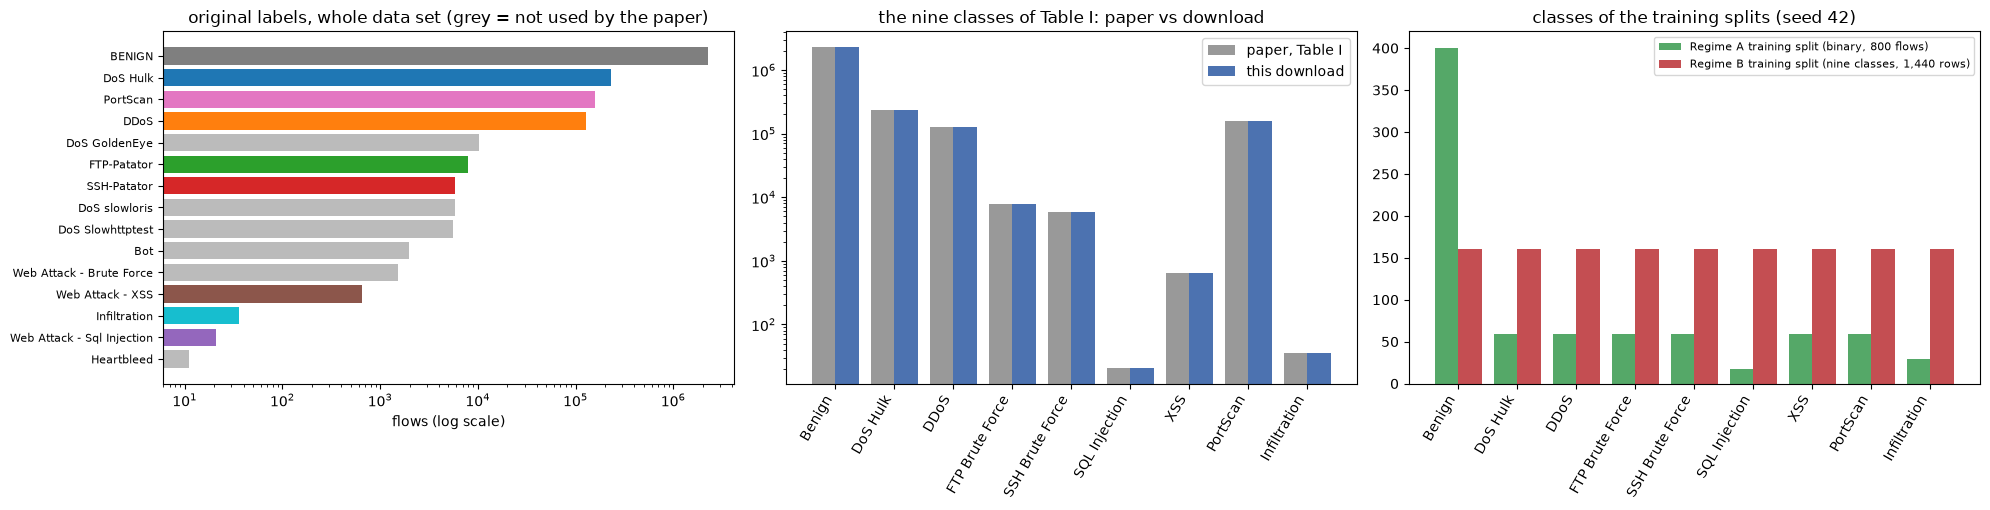

In [8]:
SPV = {"binary": make_split("binary", "paper", SEED), "nine": make_split("nine", "paper", SEED)}
DV = {k: prepare(v) for k, v in SPV.items()}
pr = DV["nine"]["prep"]
sel = [CANDIDATES[j] for j in pr.sel_]
print("Top-10 features by mutual information (nine-class training split, seed %d):" % SEED)
for r, j in enumerate(pr.sel_): print(f"  {r+1:2d}. {CANDIDATES[j]:32s} MI = {pr.scores_[j]:.3f} nats")
print("\nTable II of the paper lists:", ", ".join(PAPER_TOP10))
print("overlap with the paper's list: %d of 10  (%s)" % (len(set(sel) & set(PAPER_TOP10)), ", ".join(sorted(set(sel) & set(PAPER_TOP10)))))

PALETTE = dict(zip(CLASSES, ["#7f7f7f", "#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2", "#17becf"]))
fig, axes = plt.subplots(1, 3, figsize=(20, 5.2))
raw = pd.Series(META["raw_label_counts"]).sort_values()
axes[0].barh(raw.index, raw.values, color=[PALETTE.get(CLASS_OF.get(k, ""), "#bbbbbb") for k in raw.index]); axes[0].set_xscale("log")
axes[0].set_xlabel("flows (log scale)"); axes[0].set_title("original labels, whole data set (grey = not used by the paper)"); axes[0].tick_params(axis="y", labelsize=8)
w = 0.4; xs = np.arange(len(CLASSES))
axes[1].bar(xs - w / 2, [PAPER_TABLE_I[c] for c in CLASSES], w, label="paper, Table I", color="#999999")
axes[1].bar(xs + w / 2, [cmp.loc[c, "this download (all files)"] for c in CLASSES], w, label="this download", color="#4c72b0")
axes[1].set_yscale("log"); axes[1].set_xticks(xs); axes[1].set_xticklabels(CLASSES, rotation=60, ha="right"); axes[1].legend(); axes[1].set_title("the nine classes of Table I: paper vs download")
a_tr = pd.Series(CID[SPV["binary"]["itr"]]).value_counts().reindex(range(9)).values
b_tr = pd.Series(CID[SPV["nine"]["itr"]]).value_counts().reindex(range(9)).values
axes[2].bar(xs - w / 2, a_tr, w, label="Regime A training split (binary, 800 flows)", color="#55a868"); axes[2].bar(xs + w / 2, b_tr, w, label="Regime B training split (nine classes, 1,440 rows)", color="#c44e52")
axes[2].set_xticks(xs); axes[2].set_xticklabels(CLASSES, rotation=60, ha="right"); axes[2].legend(fontsize=8); axes[2].set_title(f"classes of the training splits (seed {SEED})")
plt.tight_layout(); plt.show()

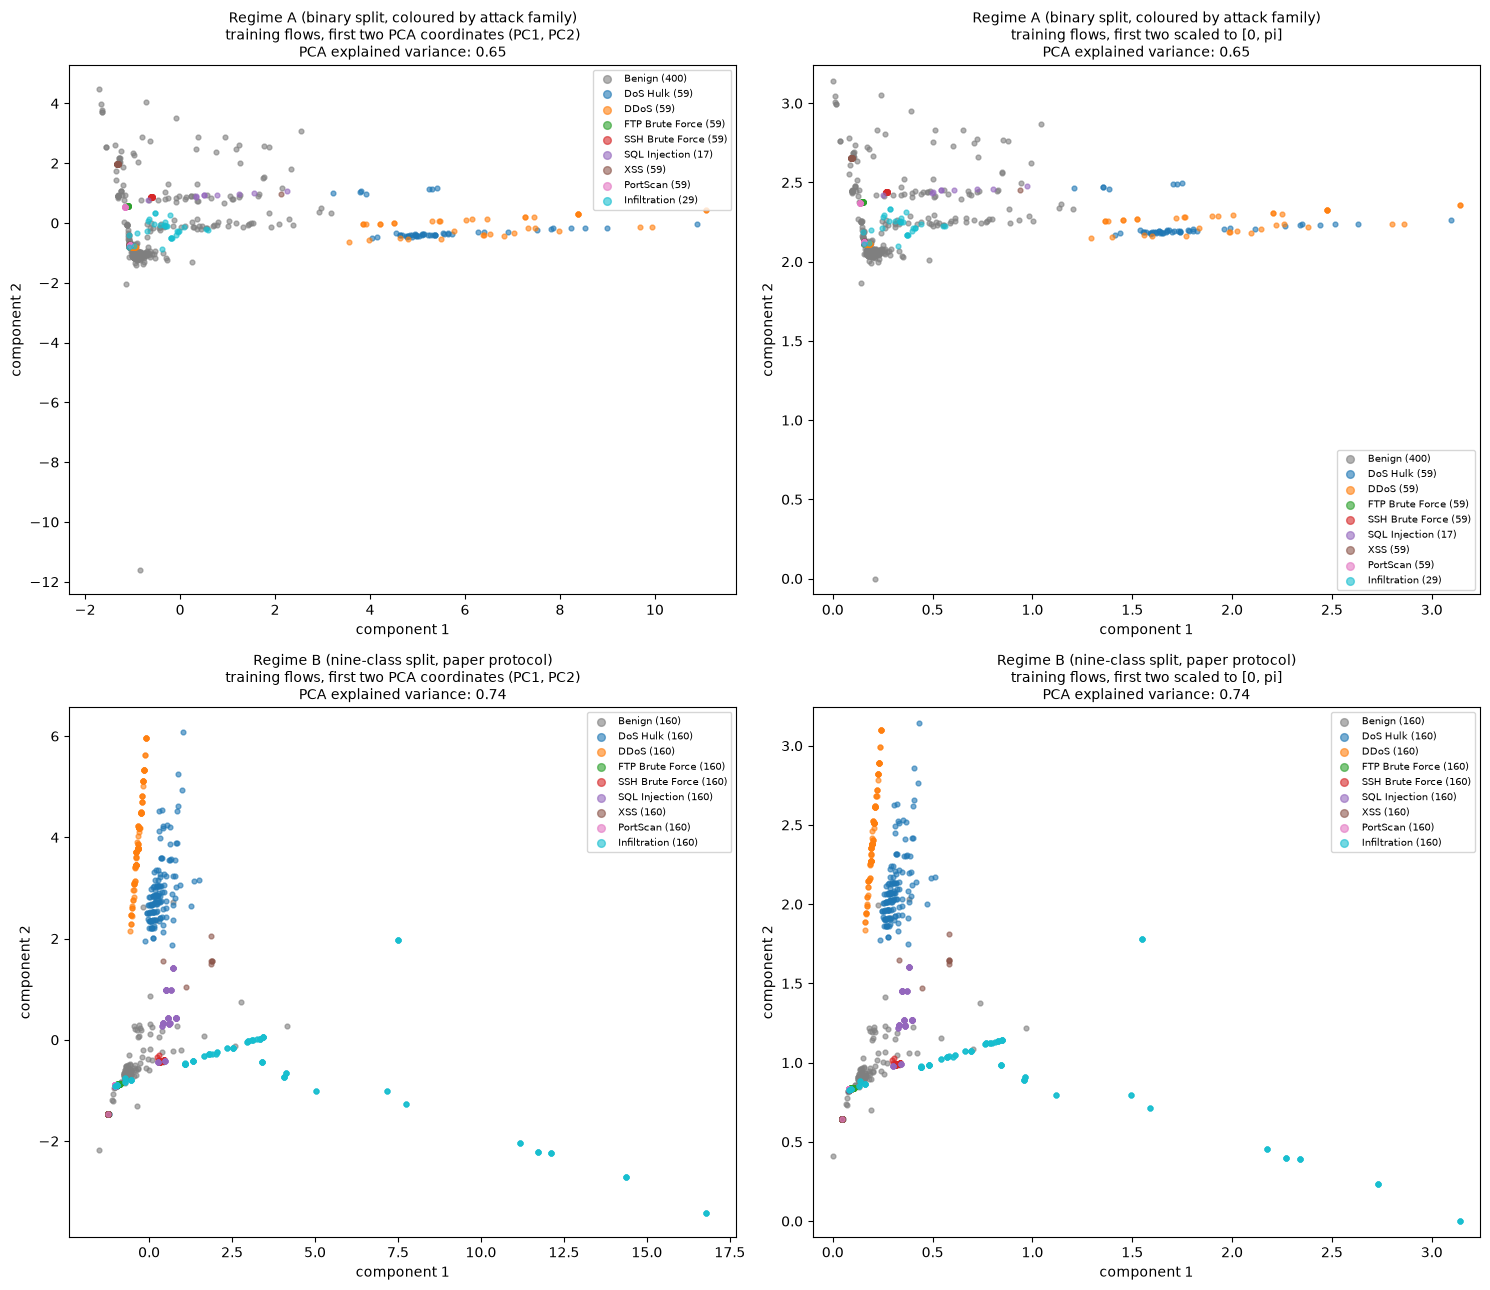

In [9]:
# 2-D scatter of the REAL training flows coloured by their ground-truth class (nine attack families kept in both regimes).
# Left: the first two PCA coordinates of the 10 selected, z-scored features (PCA fitted on the training split).
# Right: the same two coordinates min-max scaled to [0, pi] (fitted on the training split), i.e. what a plain angle encoding would receive.
fig, axes = plt.subplots(2, 2, figsize=(15, 13))
for r, (key, ttl) in enumerate((("binary", "Regime A (binary split, coloured by attack family)"), ("nine", "Regime B (nine-class split, paper protocol)"))):
    d = DV[key]; pca = PCA(2, random_state=SEED).fit(d["Ztr"]); P = pca.transform(d["Ztr"]); A = MinMaxScaler((0, np.pi)).fit(P).transform(P)
    for c, (XY, sub) in enumerate(((P, "PCA coordinates (PC1, PC2)"), (A, "scaled to [0, pi]"))):
        ax = axes[r, c]
        for k, name in enumerate(CLASSES):
            m = d["ctr"] == k
            ax.scatter(XY[m, 0], XY[m, 1], s=12, alpha=0.6, color=PALETTE[name], label=f"{name} ({m.sum()})", rasterized=True)
        ax.set_title(f"{ttl}\ntraining flows, first two {sub}\nPCA explained variance: {pca.explained_variance_ratio_.sum():.2f}", fontsize=10)
        ax.set_xlabel("component 1"); ax.set_ylabel("component 2"); ax.legend(fontsize=7, markerscale=1.6, loc="best")
        if c == 1: ax.set_xlim(-0.1, np.pi + 0.1); ax.set_ylim(-0.1, np.pi + 0.1)
plt.tight_layout(); plt.show()

**What to see.** Z-scored flow features are heavy-tailed (a few extreme flows dominate each column), so the 2-D PCA picture is a dense core near the origin with streaks and a few far outliers, and the [0, pi] panel squeezes the core into a corner. DoS Hulk and DDoS form streaks towards large values of the second component, Infiltration flows spread out along the first component up to far outliers, while Benign, the two brute-force classes, XSS and SQL Injection overlap in the dense core. Two coordinates are not what the models see (they use ten), so the plot illustrates the difficulty rather than the accuracy. Note also that the SQL Injection and Infiltration training points in Regime B are *repeated flows*: the paper's "200 per class" for these classes consists of 21 and 36 distinct flows (see the table above), so the points drawn on top of each other are copies.

## Quantum Circuit Architecture

The quantum model of the paper is a **non-parametric feature map**: `|psi(x)> = U(x)|0>^10` followed by the fidelity kernel `K(x, x') = |<psi(x)|psi(x')>|^2` (Eq. 10). There are **no trainable circuit parameters**; only the classical SVM on the kernel matrix is trained. The paper's models are

1. the **`ZZFeatureMap`** (the model of Regimes A and B): Hadamards, `P(2 x_j)` on every qubit, and for every neighbouring pair `CX - P(2 (pi - x_j)(pi - x_{j+1})) - CX` (the paper's Eq. 13 with nearest-neighbour entanglement), repeated `reps = 10` times (Section III-G);
2. the **`ZFeatureMap`** and a **`PauliFeatureMap`** of Table IV (the paper gives no details for these two: here `reps = REPS_T4`, Pauli strings `Z`, `Y`, `ZZ` with linear entanglement, `# CHOICE`).

Assumptions where the paper omits circuit details: the data enter as angles *after the z-score* with no further scaling in the literal model (the tuned model multiplies them by a scale chosen on the training split); the paper's Eq. 9 shows the Hadamard layer once, Section III-G says `ZZFeatureMap` with `reps = 10`, which repeats the Hadamard layer every time (Qiskit's definition); the entanglement is linear as in Eq. 13 rather than Qiskit's default `full`. The `Statevector` evaluation below is exact (no shot noise, no hardware noise), which is also what the paper's "Aer simulator" estimates up to sampling error.

The circuits below are the Qiskit objects that are **executed** (the big kernel matrices use a NumPy simulator that interprets exactly this gate list; the equivalence is asserted further down).

In [10]:
FIXED_1Q = {
    "h":    np.array([[1, 1], [1, -1]], complex) / np.sqrt(2),
    "x":    np.array([[0, 1], [1, 0]], complex),
    "y":    np.array([[0, -1j], [1j, 0]], complex),
    "z":    np.array([[1, 0], [0, -1]], complex),
    "s":    np.array([[1, 0], [0, 1j]], complex),
    "sdg":  np.array([[1, 0], [0, -1j]], complex),
    "sx":   np.array([[1 + 1j, 1 - 1j], [1 - 1j, 1 + 1j]], complex) / 2,
    "sxdg": np.array([[1 - 1j, 1 + 1j], [1 + 1j, 1 - 1j]], complex) / 2,
}

SUPPORTED_GATES = set(FIXED_1Q) | {"p", "u1", "rz", "cx", "barrier"}

def elementary(circuit):
    """Decompose a feature map until only elementary gates (h, p, cx, sx, sdg, ...) are left: the gate list that is simulated and drawn."""
    qc = circuit
    for _ in range(8):
        if all(i.operation.name in SUPPORTED_GATES for i in qc.data): break
        qc = qc.decompose()
    return qc

class GateListSimulator:
    """Exact statevector simulation of a parametrised Qiskit circuit for MANY data points at once.
    The gate list is read from the very circuit that is drawn in the 'Quantum Circuit Architecture' section (decomposed to
    h / p / cx / sx / sdg ... gates). Runs of data-independent single-qubit gates are merged into one 2x2 matrix per qubit, runs of
    diagonal gates (p, and the cx-p-cx pattern) into one phase vector (the angle expressions are lambdified with sympy and
    evaluated for all samples as NumPy vectors); any other gate (a bare cx) acts on a (N, 2, ..., 2) tensor."""
    def __init__(self, circuit):
        self.n = n = circuit.num_qubits
        qc = elementary(circuit)
        self.params = sorted(circuit.parameters, key=lambda p: p.index if hasattr(p, "index") else str(p))
        self.symbols = [sympy.Symbol(p.name) for p in self.params]
        ops = []
        for inst in qc.data:
            name = inst.operation.name
            qs = [qc.find_bit(q).index for q in inst.qubits]
            ang = None
            if inst.operation.params:
                e = inst.operation.params[0]
                if hasattr(e, "sympify"):
                    ex = e.sympify()
                    ang = sympy.lambdify(self.symbols, ex, "numpy") if ex.free_symbols else float(ex)
                else:
                    ang = float(e)
            if name not in tuple(FIXED_1Q) + ("p", "u1", "rz", "cx", "barrier"):
                raise NotImplementedError(name)
            if name != "barrier":
                ops.append((name, qs, ang))
        self.gate_count = len(ops)
        fused, i = [], 0                        # cx(c,t) p(theta on t) cx(c,t)  ->  one diagonal gate: phase exp(i theta) when the two bits differ
        while i < len(ops):
            if (i + 2 < len(ops) and ops[i][0] == "cx" and ops[i + 1][0] == "p" and ops[i + 2][0] == "cx"
                    and ops[i][1] == ops[i + 2][1] and ops[i + 1][1][0] == ops[i][1][1]):
                fused.append(("zzphase", ops[i][1], ops[i + 1][2])); i += 3
            else:
                fused.append(ops[i]); i += 1
        s = np.arange(2 ** n)                   # basis-state bit tables (qubit 0 = most significant bit of the index)
        bit = np.array([(s >> (n - 1 - q)) & 1 for q in range(n)], float)
        self.blocks, i = [], 0
        while i < len(fused):
            kind = fused[i][0]
            if kind in FIXED_1Q:
                M = [np.eye(2, dtype=complex) for _ in range(n)]
                while i < len(fused) and fused[i][0] in FIXED_1Q:
                    nm, qs, _ = fused[i]; M[qs[0]] = FIXED_1Q[nm] @ M[qs[0]]; i += 1
                self.blocks.append(("mat", [(q, M[q]) for q in range(n) if not np.allclose(M[q], np.eye(2))]))
            elif kind in ("p", "u1", "rz", "zzphase"):
                angs, inds = [], []
                while i < len(fused) and fused[i][0] in ("p", "u1", "rz", "zzphase"):
                    nm, qs, ang = fused[i]
                    if nm in ("p", "u1"): angs.append(ang); inds.append(bit[qs[0]])
                    elif nm == "rz":      angs.append(ang); inds.append(bit[qs[0]] - 0.5)
                    else:                 angs.append(ang); inds.append(np.abs(bit[qs[0]] - bit[qs[1]]))
                    i += 1
                self.blocks.append(("diag", angs, np.array(inds)))
            else:
                self.blocks.append(("cx", fused[i][1])); i += 1

    def run(self, X, chunk=64):
        """X: (N, n_params), the values of the circuit parameters in circuit.parameters order. Returns the (N, 2**n) complex statevectors
        (qubit 0 = most significant index bit, NOT Qiskit's little-endian order; the kernel does not depend on the ordering).
        Samples are processed in chunks so that the working arrays stay in the CPU cache."""
        X = np.asarray(X, float)
        return np.concatenate([self._run(X[i:i + chunk]) for i in range(0, len(X), chunk)], axis=0)

    def _run(self, X):
        N, n = X.shape[0], self.n
        psi = np.zeros((N, 2 ** n), complex); psi[:, 0] = 1.0
        cols = [X[:, j] for j in range(X.shape[1])]
        for blk in self.blocks:
            if blk[0] == "mat":
                for q, M in blk[1]:                     # one 2x2 matrix per qubit (a Kronecker product), applied qubit by qubit
                    T = psi.reshape(N * 2 ** q, 2, 2 ** (n - 1 - q)); a, b = T[:, 0, :], T[:, 1, :]
                    psi = np.stack([M[0, 0] * a + M[0, 1] * b, M[1, 0] * a + M[1, 1] * b], axis=1).reshape(N, 2 ** n)
            elif blk[0] == "diag":
                TH = np.stack([np.full(N, a) if not callable(a) else a(*cols) for a in blk[1]], axis=1)      # (N, gates)
                psi *= np.exp(1j * (TH @ blk[2]))
            else:
                c, t = blk[1]; T = psi.reshape((N,) + (2,) * n)
                i0 = [slice(None)] * (n + 1); i0[c + 1] = 1; i0[t + 1] = 0
                i1 = list(i0); i1[t + 1] = 1
                a = T[tuple(i0)].copy(); T[tuple(i0)] = T[tuple(i1)]; T[tuple(i1)] = a
        return psi

def fidelity_kernel(SA, SB=None):
    """K(x, x') = |<psi(x)|psi(x')>|^2 from two sets of statevectors."""
    SB = SA if SB is None else SB
    return np.abs(SA.conj() @ SB.T) ** 2

In [11]:
def make_feature_map(kind, n=N_QUBITS, reps=1):
    """The three feature maps of the paper's Table IV (linear = nearest-neighbour entanglement, as in Eq. 13)."""
    if kind == "Z":     return z_feature_map(n, reps=reps)
    if kind == "ZZ":    return zz_feature_map(n, reps=reps, entanglement="linear")
    if kind == "Pauli": return pauli_feature_map(n, reps=reps, paulis=["Z", "Y", "ZZ"], entanglement="linear")        # CHOICE: Z, Y and ZZ terms
    raise ValueError(kind)

_SIMS = {}
def get_sim(kind, reps):
    if (kind, reps) not in _SIMS: _SIMS[(kind, reps)] = GateListSimulator(make_feature_map(kind, N_QUBITS, reps))
    return _SIMS[(kind, reps)]

USED = [("ZZ", REPS, "Regimes A and B (the paper's model)"), ("Z", REPS_T4, "Table IV"), ("Pauli", REPS_T4, "Table IV")] + ([("ZZ", 2, "extension (not in the paper)")] if EXTENSION else [])
rows = []
for kind, reps, why in USED:
    fm = make_feature_map(kind, N_QUBITS, reps); el = elementary(fm)
    ops = {k: v for k, v in el.count_ops().items() if k != "barrier"}
    rows.append(dict(map=f"{kind}FeatureMap, reps={reps}", used_for=why, qubits=fm.num_qubits, depth=el.depth(), gates=el.size(), two_qubit_gates=ops.get("cx", 0),
                     data_parameters=fm.num_parameters, trainable_parameters=0, gate_types=dict(sorted(ops.items()))))
print(pd.DataFrame(rows).set_index("map").to_string())

                                                    used_for  qubits  depth  gates  two_qubit_gates  data_parameters  trainable_parameters                                          gate_types
map                                                                                                                                                                                           
ZZFeatureMap, reps=10    Regimes A and B (the paper's model)      10    101    470              180               10                     0                     {'cx': 180, 'h': 100, 'p': 190}
ZFeatureMap, reps=2                                 Table IV      10      4     40                0               10                     0                                  {'h': 20, 'p': 20}
PauliFeatureMap, reps=2                             Table IV      10     43    154               36               10                     0  {'cx': 36, 'h': 20, 'p': 58, 'sx': 20, 'sxdg': 20}


Figure 1: ZZFeatureMap, 10 qubits, reps=1 (x[j] = the j-th selected, z-scored feature). The executed model repeats this block reps=10 times.


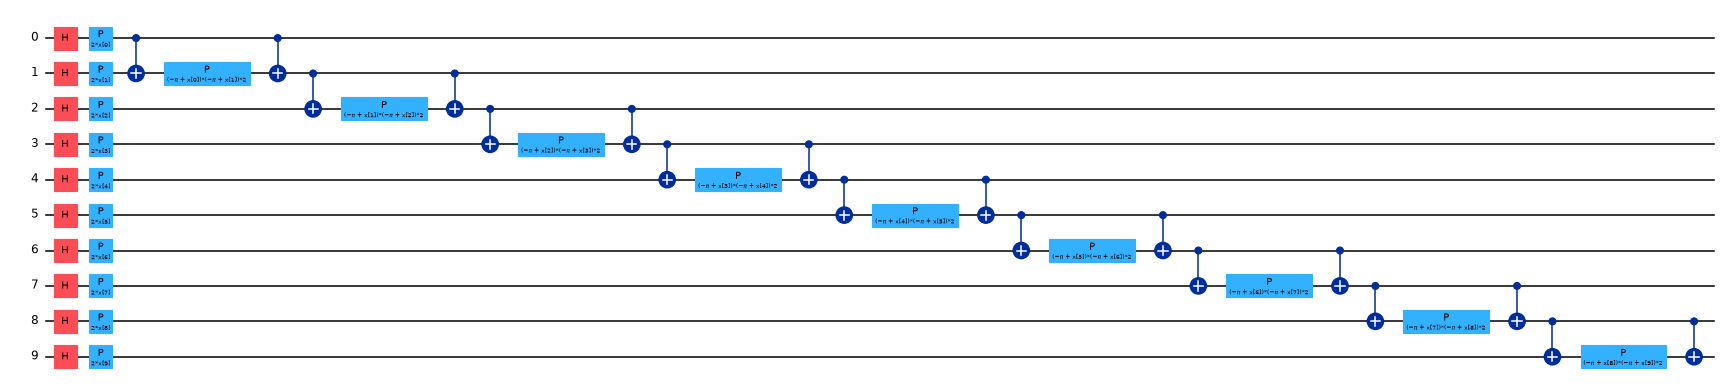

In [12]:
# Figure 1: the ZZFeatureMap of the paper, ONE repetition drawn at gate level (the executed circuit repeats this block REPS times).
fm1 = make_feature_map("ZZ", N_QUBITS, 1)
print(f"Figure 1: ZZFeatureMap, 10 qubits, reps=1 (x[j] = the j-th selected, z-scored feature). The executed model repeats this block reps={REPS} times.")
display(elementary(fm1).draw("mpl", fold=-1, scale=0.55))

Figure 2: the executed ZZFeatureMap, 10 qubits, reps=10: depth 101, 470 gates, 0 trainable parameters.


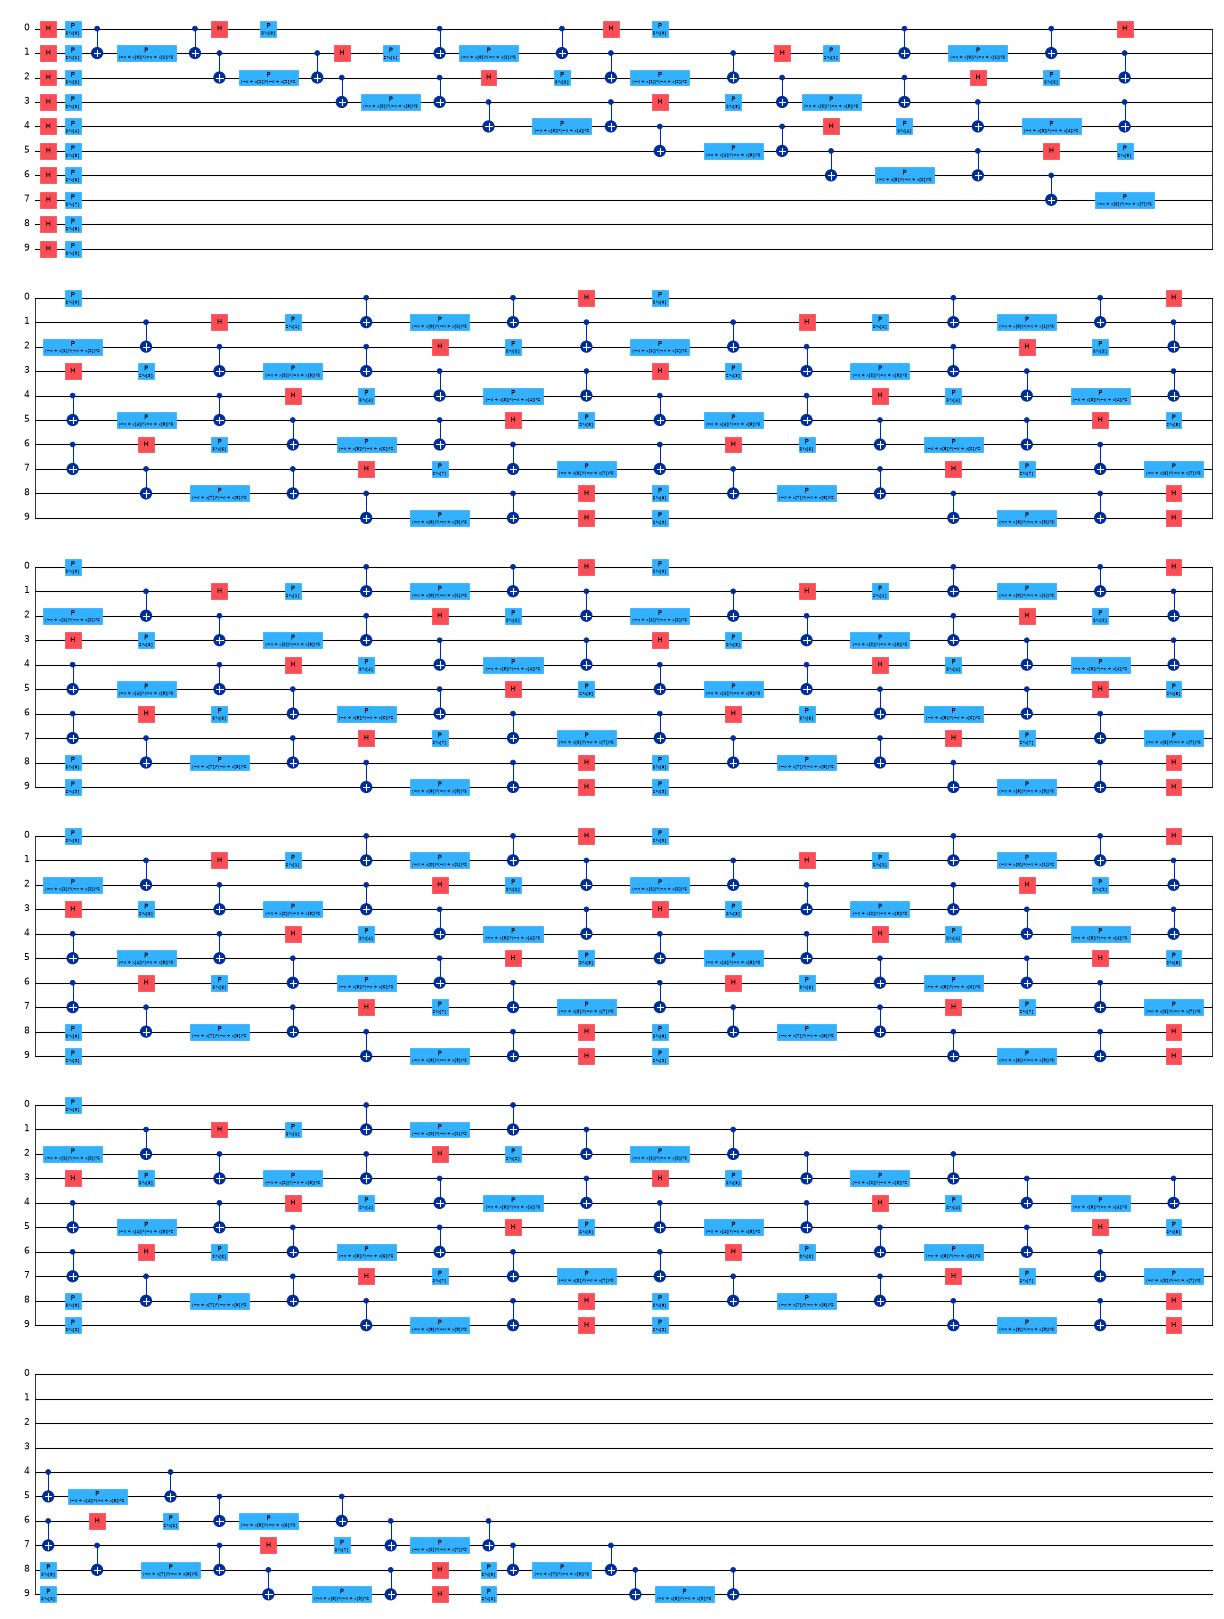

In [13]:
# Figure 2: the circuit that is actually executed by the paper's model: ZZFeatureMap with reps=10, folded (10 repetitions of the block of Figure 1).
fmR = make_feature_map("ZZ", N_QUBITS, REPS)
print(f"Figure 2: the executed ZZFeatureMap, 10 qubits, reps={REPS}: depth {elementary(fmR).depth()}, {elementary(fmR).size()} gates, 0 trainable parameters.")
display(elementary(fmR).draw("mpl", fold=48, scale=0.38))

Figure 3: ZFeatureMap, 10 qubits, reps=1 (single-qubit rotations only: no entanglement, the kernel factorises over qubits)


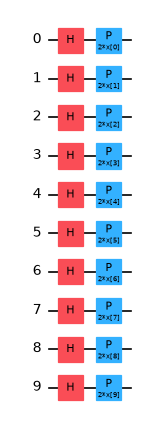

Figure 4: PauliFeatureMap with Pauli strings Z, Y, ZZ, 10 qubits, reps=1 (CHOICE: the paper does not specify its Pauli map)


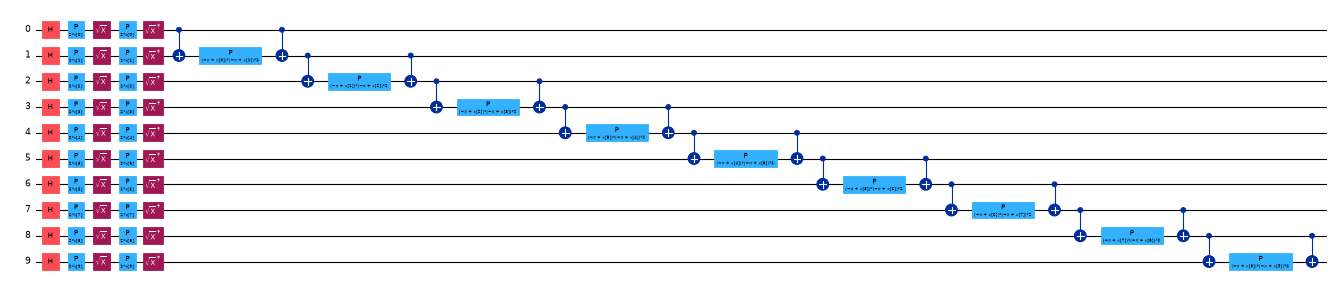

In [14]:
# Figures 3 and 4: the two other architectures of Table IV (one repetition each).
print("Figure 3: ZFeatureMap, 10 qubits, reps=1 (single-qubit rotations only: no entanglement, the kernel factorises over qubits)")
display(elementary(make_feature_map("Z", N_QUBITS, 1)).draw("mpl", fold=-1, scale=0.6))
print("Figure 4: PauliFeatureMap with Pauli strings Z, Y, ZZ, 10 qubits, reps=1 (CHOICE: the paper does not specify its Pauli map)")
display(elementary(make_feature_map("Pauli", N_QUBITS, 1)).draw("mpl", fold=-1, scale=0.4))

**Equivalence check.** The NumPy simulator above reads the gate list of the circuits just drawn (`elementary(...)`), merges layers and evaluates all flows at once. The cell below asserts that its kernel values equal (1) the overlaps of Qiskit's `Statevector` of the bound circuit, (2) Qiskit's `FidelityStatevectorKernel`, and (3) the probability of the all-zero outcome of the compute-uncompute circuit `U(y)^dagger U(x)` sampled on the `AerSimulator` (what a quantum computer would run for every pair of flows).

In [15]:
rg = np.random.default_rng(SEED)
dz = DV["nine"]["Ztr"]
XA, XB = dz[rg.choice(len(dz), 6, replace=False)], dz[rg.choice(len(dz), 5, replace=False)]
rows = []
for kind, reps, why in USED:
    fm = make_feature_map(kind, N_QUBITS, reps); sim = get_sim(kind, reps)
    for s in (1.0, 0.1):
        K_sim = fidelity_kernel(sim.run(s * XA), sim.run(s * XB))
        K_sv = np.array([[abs(np.vdot(Statevector(fm.assign_parameters(s * a)).data, Statevector(fm.assign_parameters(s * b)).data)) ** 2 for b in XB] for a in XA])
        K_fsk = FidelityStatevectorKernel(feature_map=fm).evaluate(s * XA, s * XB)
        assert np.allclose(K_sim, K_sv, atol=1e-10) and np.allclose(K_sim, K_fsk, atol=1e-10), (kind, reps, s)
        rows.append(dict(map=f"{kind}, reps={reps}", angle_scale=s, max_diff_vs_Statevector=np.abs(K_sim - K_sv).max(), max_diff_vs_FidelityStatevectorKernel=np.abs(K_sim - K_fsk).max()))
print(pd.DataFrame(rows).to_string(index=False)); print("all equivalence assertions passed")

# (3) the compute-uncompute circuit on the Aer simulator for a few pairs (ZZ map, reps=REPS, angle scale 0.1)
fm = make_feature_map("ZZ", N_QUBITS, REPS); sim = get_sim("ZZ", REPS)
from qiskit.circuit import ParameterVector
px, py = ParameterVector("x", N_QUBITS), ParameterVector("y", N_QUBITS)
kc = make_feature_map("ZZ", N_QUBITS, REPS).assign_parameters(list(px)).compose(make_feature_map("ZZ", N_QUBITS, REPS).assign_parameters(list(py)).inverse()); kc.measure_all()
aer = AerSimulator(seed_simulator=SEED); tkc = transpile(kc, aer, optimization_level=0, seed_transpiler=SEED)
pairs = [(0.1 * XA[i], 0.1 * XA[i] + 0.02 * rg.normal(size=N_QUBITS)) for i in range(4)]
res = aer.run([tkc.assign_parameters(dict(zip(list(px) + list(py), np.concatenate([a, b])))) for a, b in pairs], shots=200_000).result()
p0 = np.array([res.get_counts(i).get("0" * N_QUBITS, 0) / 200_000 for i in range(len(pairs))])
exact = np.array([fidelity_kernel(sim.run(a[None]), sim.run(b[None]))[0, 0] for a, b in pairs])
print("\nAer, compute-uncompute circuit (200k shots), P(0...0):", np.round(p0, 4)); print("exact kernel from the simulator              :", np.round(exact, 4))
assert np.allclose(p0, exact, atol=0.01)
print(f"kernel circuit U(y)^dagger U(x) + measurement: {tkc.num_qubits} qubits, depth {tkc.depth()}, {tkc.size()} gates, 0 trainable parameters")

          map  angle_scale  max_diff_vs_Statevector  max_diff_vs_FidelityStatevectorKernel
  ZZ, reps=10          1.0             2.892131e-14                           2.892131e-14
  ZZ, reps=10          0.1             1.498801e-14                           1.476597e-14
    Z, reps=2          1.0             1.998401e-15                           1.998401e-15
    Z, reps=2          0.1             3.330669e-15                           3.330669e-15
Pauli, reps=2          1.0             6.661338e-15                           6.661338e-15
Pauli, reps=2          0.1             5.467848e-15                           5.467848e-15
all equivalence assertions passed



Aer, compute-uncompute circuit (200k shots), P(0...0): [0.6787 0.786  0.4912 0.551 ]
exact kernel from the simulator              : [0.6784 0.7867 0.4941 0.5523]
kernel circuit U(y)^dagger U(x) + measurement: 10 qubits, depth 203, 950 gates, 0 trainable parameters


In [16]:
# Cost of the kernel: Qiskit's FidelityStatevectorKernel versus the NumPy gate-list simulator (same circuit, same numbers), per flow.
Xt = dz[:60]; fmR = make_feature_map("ZZ", N_QUBITS, REPS)
t0 = time.time(); K_q = FidelityStatevectorKernel(feature_map=fmR).evaluate(Xt, Xt); t_fsk = (time.time() - t0) / len(Xt)
t0 = time.time(); K_n = fidelity_kernel(get_sim("ZZ", REPS).run(Xt)); t_np = (time.time() - t0) / len(Xt)
assert np.allclose(K_q, K_n, atol=1e-10)
print(f"ZZ map, reps={REPS}, 10 qubits: FidelityStatevectorKernel {1000 * t_fsk:.0f} ms per flow, NumPy gate-list simulator {1000 * t_np:.0f} ms per flow (identical kernels)")
print(f"=> the 1,800 flows of Regime B need about {1800 * t_fsk / 60:.1f} min of statevector simulation with Qiskit's class for ONE angle scale, and {1800 * t_np / 60:.1f} min with the NumPy simulator "
      f"(the paper's Table V reports 0.005 s per sample on its own hardware; the numbers are not comparable).")

ZZ map, reps=10, 10 qubits: FidelityStatevectorKernel 65 ms per flow, NumPy gate-list simulator 8 ms per flow (identical kernels)
=> the 1,800 flows of Regime B need about 1.9 min of statevector simulation with Qiskit's class for ONE angle scale, and 0.2 min with the NumPy simulator (the paper's Table V reports 0.005 s per sample on its own hardware; the numbers are not comparable).


### What the kernel looks like on real flows

For a deep feature map (`reps = 10`) and angles of the size of a z-score (about one radian, much larger for outliers) the kernel values are either close to 1 (two flows with nearly identical features, e.g. two PortScan probes) or close to 0 (any other pair); there is little in between, so the kernel behaves like a nearest-neighbour rule on near-duplicates. A small **angle scale** (a bandwidth, not in the paper) multiplies the features before they enter the circuit and widens the range of kernel values. The figure shows the kernel matrix of real training flows sorted by class (25 per class) and the distribution of its off-diagonal values for three scales.

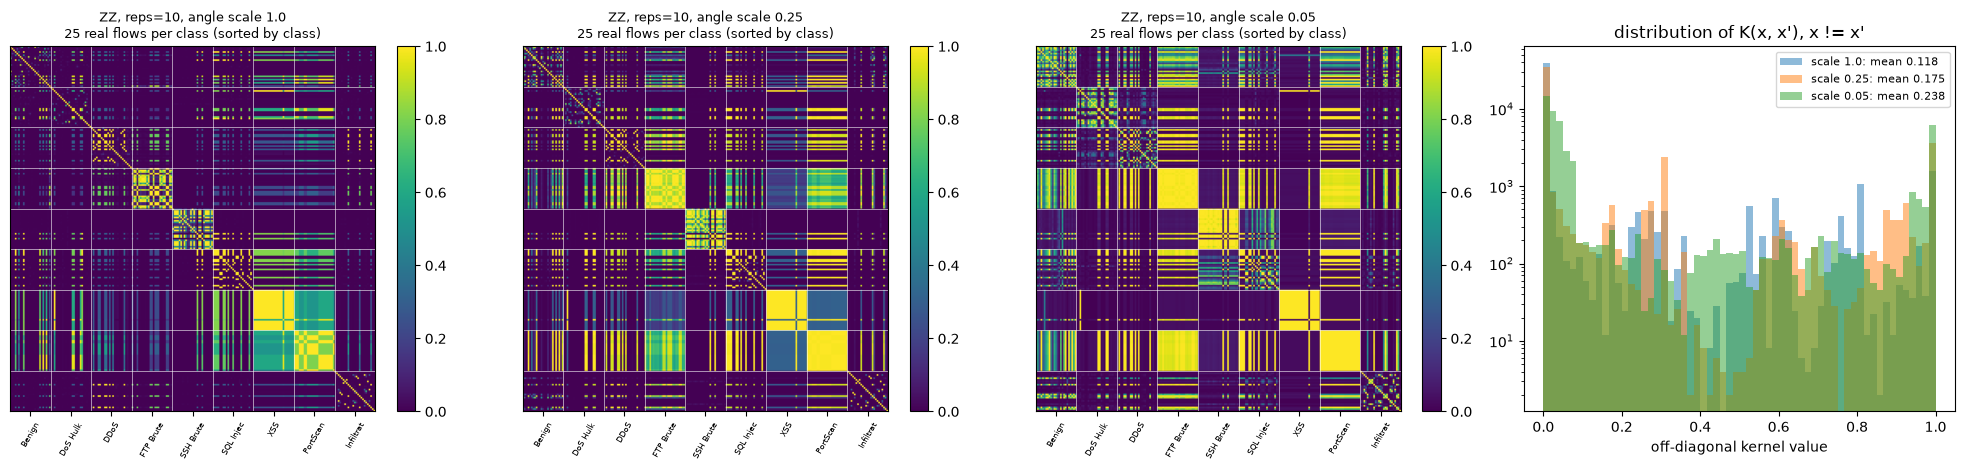

In [17]:
d = DV["nine"]; sim = get_sim("ZZ", REPS)
order = np.concatenate([np.flatnonzero(d["ytr"] == k)[:25] for k in range(9)])
scales_show = [1.0, 0.25, 0.05]
fig, axes = plt.subplots(1, len(scales_show) + 1, figsize=(5 * (len(scales_show) + 1), 4.6))
offs = {}
for ax, s in zip(axes, scales_show):
    S = sim.run(s * d["Ztr"][order]); K = fidelity_kernel(S)
    im = ax.imshow(K, cmap="viridis", vmin=0, vmax=1)
    edges = np.arange(25, len(order), 25)
    for e in edges: ax.axhline(e - .5, color="w", lw=.4); ax.axvline(e - .5, color="w", lw=.4)
    ax.set_title(f"ZZ, reps={REPS}, angle scale {s}\n25 real flows per class (sorted by class)", fontsize=9); plt.colorbar(im, ax=ax, fraction=0.046)
    ax.set_xticks(np.arange(12, len(order), 25)); ax.set_xticklabels([c[:9] for c in CLASSES], rotation=60, fontsize=6); ax.set_yticks([])
    offs[s] = K[~np.eye(len(order), dtype=bool)]
for s, o in offs.items(): axes[-1].hist(o, bins=60, range=(0, 1), alpha=0.5, label=f"scale {s}: mean {o.mean():.3f}", log=True)
axes[-1].set_xlabel("off-diagonal kernel value"); axes[-1].set_title("distribution of K(x, x'), x != x'"); axes[-1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3. Models: the QSVM and the paper's classical competitors

All models see the **same 10 z-scored numbers per flow** (the output of the training-split preprocessing).

* **QSVM (literal).** `ZZFeatureMap(10 qubits, reps = 10, linear entanglement)` with the features as angles (scale 1), fidelity kernel (Eq. 10), `SVC(kernel="precomputed")`. For nine classes: **one-vs-rest** with nine binary SVMs on the same kernel matrix and `y_hat = argmax_k f_k(x)` (Eq. 15). `C` in `{0.1, 1, 10, 100}` by `CV_FOLDS`-fold stratified CV (macro-F1) on the training split.
* **QSVM (tuned)** (not in the paper). The same, with the angle scale chosen from `SCALES` and `C` from the wider grid `C_WIDE` (adds 1000), jointly by the same cross-validation on the training split only. Scale 1 is part of the grid, so the tuned model is never worse in cross-validation than the literal one.
* **SVM (RBF).** `C in {0.1, 1, 10, 100}`, `gamma in {0.01, 0.1, 1}`, `CV_FOLDS`-fold CV (macro-F1), directly in multiclass mode. **SVM (RBF, wide grid)** (not in the paper) uses `C_WIDE` and `GAMMA_WIDE` (up to 100), so that the classical model gets the same extra freedom as the tuned quantum model.
* **Random Forest** (200 trees) and **XGBoost** (200 rounds, depth 6, learning rate 0.1), natively multiclass.
* *Extension (full run only):* the ZZ map with `reps = 2`, tuned the same way.

Model selection uses the training split only; the preprocessing is fitted once on the training split (the paper refits it inside every fold; this only affects the choice of hyper-parameters, never the test set). Metrics as in the paper: accuracy, precision, recall, F1 (attack = positive class in Regime A; macro-averaged in Regime B).

In [18]:
def metrics(y, p, nine):
    avg = "macro" if nine else "binary"
    return dict(acc=accuracy_score(y, p), prec=precision_score(y, p, average=avg, zero_division=0), rec=recall_score(y, p, average=avg, zero_division=0),
                f1=f1_score(y, p, average=avg, zero_division=0))

def ovr_scores(Ktr, y, Kte, C, classes):
    """Decision scores (n_test, n_classes) of one-vs-rest SVMs on a precomputed kernel (a single SVM for two classes)."""
    if len(classes) == 2:
        s = SVC(kernel="precomputed", C=C).fit(Ktr, y).decision_function(Kte); return np.stack([-s, s], axis=1)
    return np.stack([SVC(kernel="precomputed", C=C).fit(Ktr, (y == c).astype(int)).decision_function(Kte) for c in classes], axis=1)

def cv_macro_f1(K, y, C, classes, folds, seed):
    scores = []
    for a, b in StratifiedKFold(folds, shuffle=True, random_state=seed).split(K, y):
        p = classes[ovr_scores(K[np.ix_(a, a)], y[a], K[np.ix_(b, a)], C, classes).argmax(1)]
        scores.append(f1_score(y[b], p, average="macro", zero_division=0))
    return float(np.mean(scores))

def qsvm_fit_predict(Ztr, ytr, Zte, kind, reps, scales, seed, literal_scale=1.0):
    """Kernel from the exact statevectors of the feature map; (scale, C) by CV on the training split.
    'literal': scale 1 and C from the paper's grid; 'tuned': scale from `scales` and C from the wide grid C_WIDE, jointly by CV."""
    sim = get_sim(kind, reps); classes = np.unique(ytr)
    scales = list(dict.fromkeys([literal_scale] + list(scales)))
    best, S_tr = {}, {}
    for s in scales:
        S_tr[s] = sim.run(s * Ztr); K = fidelity_kernel(S_tr[s])
        sc = {C: cv_macro_f1(K, ytr, C, classes, CV_FOLDS, seed) for C in C_WIDE}
        Cp = max(C_GRID, key=lambda C: (sc[C], -C)); Cw = max(C_WIDE, key=lambda C: (sc[C], -C))      # best CV score, ties -> smaller C
        best[s] = dict(C_paper_grid=Cp, cv_paper_grid=sc[Cp], C_wide_grid=Cw, cv_wide_grid=sc[Cw], offdiag=float(K[~np.eye(len(K), dtype=bool)].mean()))
    s_tuned = max(scales, key=lambda s: (best[s]["cv_wide_grid"], s == literal_scale))   # ties -> the literal scale
    out = {}
    for tag, s, ck in (("literal", literal_scale, "paper_grid"), ("tuned", s_tuned, "wide_grid")):
        K = fidelity_kernel(S_tr[s]); Kte = fidelity_kernel(sim.run(s * Zte), S_tr[s]); C = best[s]["C_" + ck]
        out[tag] = dict(pred=classes[ovr_scores(K, ytr, Kte, C, classes).argmax(1)], scale=s, C=C, cv=best[s]["cv_" + ck], offdiag=best[s]["offdiag"])
    out["grid"] = best
    return out

def run_models(sp, feats="mi", light=False, ext=False):
    """Train the models on one split; returns {model: dict(pred, time, info)} and the prepared data.
    light=True skips XGBoost; ext=True adds the reps=2 extension model."""
    d = prepare(sp, feats); seed = sp["seed"]; res = {}
    cv = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=seed)
    for nm, grid in (("SVM (RBF)", {"C": C_GRID, "gamma": GAMMA_GRID}), ("SVM (RBF, wide grid)", {"C": C_WIDE, "gamma": GAMMA_WIDE})):
        t0 = time.time()
        g = GridSearchCV(SVC(kernel="rbf"), grid, cv=cv, scoring="f1_macro", n_jobs=1).fit(d["Ztr"], d["ytr"])
        res[nm] = dict(pred=g.predict(d["Zte"]), time=time.time() - t0, info=str(g.best_params_))
    t0 = time.time(); m = RandomForestClassifier(RF_TREES, random_state=seed, n_jobs=2).fit(d["Ztr"], d["ytr"])
    res["Random Forest"] = dict(pred=m.predict(d["Zte"]), time=time.time() - t0, info="")
    if not light:
        t0 = time.time(); m = XGBClassifier(n_estimators=XGB_ROUNDS, max_depth=6, learning_rate=0.1, random_state=seed, n_jobs=1, tree_method="hist").fit(d["Ztr"], d["ytr"])
        res["XGBoost"] = dict(pred=m.predict(d["Zte"]), time=time.time() - t0, info="")
    t0 = time.time(); q = qsvm_fit_predict(d["Ztr"], d["ytr"], d["Zte"], "ZZ", REPS, SCALES, seed); tq = time.time() - t0
    for tag, nm in (("literal", "QSVM literal"), ("tuned", "QSVM tuned")):
        res[nm] = dict(pred=q[tag]["pred"], time=tq, info=f"scale {q[tag]['scale']}, C {q[tag]['C']}, CV macro-F1 {q[tag]['cv']:.3f}")
    res["_qgrid"] = q["grid"]
    if ext:
        t0 = time.time(); q2 = qsvm_fit_predict(d["Ztr"], d["ytr"], d["Zte"], "ZZ", 2, SCALES, seed)
        res["QSVM reps=2 tuned"] = dict(pred=q2["tuned"]["pred"], time=time.time() - t0, info=f"scale {q2['tuned']['scale']}, C {q2['tuned']['C']}, CV macro-F1 {q2['tuned']['cv']:.3f}")
    return res, d

## 4. Main experiments: Regime A (binary) and Regime B (nine classes, both protocols)

For every seed in `SEEDS` a new sample of flows and a new split are drawn. Regime A has no repeated flows (so one protocol); Regime B is run with the paper's protocol (repeated flows cross the split) and with the leak-free protocol.

In [19]:
ROWS, PRED, INFO = [], {}, {}
T_ALL = time.time()
for seed in SEEDS:
    for regime, protocol in (("binary", "paper"), ("nine", "paper"), ("nine", "leakfree")):
        t0 = time.time(); sp = make_split(regime, protocol, seed)
        res, d = run_models(sp, ext=(EXTENSION and regime == "nine" and protocol == "paper")); nine = regime == "nine"
        for nm, r in res.items():
            if nm.startswith("_"): continue
            ROWS.append(dict(regime=regime, protocol=protocol, seed=seed, model=nm, time=r["time"], **metrics(d["yte"], r["pred"], nine)))
            PRED[(regime, protocol, seed, nm)] = (d["yte"], r["pred"], d["cte"])
            INFO[(regime, protocol, seed, nm)] = r["info"]
        INFO[(regime, protocol, seed, "_qgrid")] = res["_qgrid"]
        print(f"seed {seed} | {regime:6s} | {protocol:8s} | train {len(d['ytr'])} / test {len(d['yte'])} | {time.time()-t0:.0f} s", flush=True)
RES = pd.DataFrame(ROWS)
print(f"\nall main experiments: {(time.time()-T_ALL)/60:.1f} min")

# Robustness check (full run only): the same models on the ten features that the paper LISTS in its Table II instead of the ones the MI ranking picks here.
ROWS2 = []
if RUN_T2:
    t1 = time.time()
    for seed in SEEDS:
        for regime in ("binary", "nine"):
            res2, d2 = run_models(make_split(regime, "paper", seed), feats="table2", light=True)
            for nm, r in res2.items():
                if not nm.startswith("_"): ROWS2.append(dict(regime=regime, protocol="paper", seed=seed, model=nm, time=r["time"], **metrics(d2["yte"], r["pred"], regime == "nine")))
        print(f"seed {seed} | Table II feature set done ({time.time()-t1:.0f} s)", flush=True)
RES_T2 = pd.DataFrame(ROWS2)

seed 42 | binary | paper    | train 800 / test 200 | 40 s


seed 42 | nine   | paper    | train 1440 / test 360 | 105 s


seed 42 | nine   | leakfree | train 1440 / test 292 | 81 s



all main experiments: 3.8 min


seed 42 | Table II feature set done (126 s)


In [20]:
def summary(res, cols=("acc", "prec", "rec", "f1")):
    g = res.groupby("model", sort=False)
    mean, std = g[list(cols)].mean() * 100, g[list(cols)].std(ddof=0) * 100
    out = pd.DataFrame({c: [f"{m:.1f} +/- {s:.1f}" if len(SEEDS) > 1 else f"{m:.1f}" for m, s in zip(mean[c], std[c])] for c in cols}, index=mean.index)
    out["time (s)"] = g["time"].mean().round(1).values
    return out
for (regime, protocol), title in ((("binary", "paper"), "Regime A (binary, 1,000 flows; 200 test flows per seed)"),
                                  (("nine", "paper"), "Regime B, protocol 'paper' (nine classes, 1,800 rows, 360 test rows per seed; macro averages)"),
                                  (("nine", "leakfree"), "Regime B, protocol 'leakfree' (distinct flows only in the test set; macro averages)")):
    print("\n" + title + f"   [mean over seeds {SEEDS}]"); print(summary(RES[(RES.regime == regime) & (RES.protocol == protocol)]).to_string())
print("\nSelected hyper-parameters (seed %d):" % SEED)
for regime, protocol in (("binary", "paper"), ("nine", "paper"), ("nine", "leakfree")):
    for nm in ("SVM (RBF)", "SVM (RBF, wide grid)", "QSVM literal", "QSVM tuned"):
        print(f"  {regime:6s} {protocol:8s} {nm:21s}: {INFO[(regime, protocol, SEED, nm)]}")
print("\nCross-validation macro-F1 of the QSVM on the training split, per angle scale (nine classes, paper protocol, seed %d):" % SEED)
print(pd.DataFrame(INFO[("nine", "paper", SEED, "_qgrid")]).T.round(3).to_string())
if len(RES_T2):
    print("\nRobustness: the ten features LISTED in the paper's Table II instead of the MI selection (paper protocol, mean over seeds):")
    for regime in ("binary", "nine"):
        print(f"\n  {regime}"); print(summary(RES_T2[RES_T2.regime == regime]).to_string())


Regime A (binary, 1,000 flows; 200 test flows per seed)   [mean over seeds [42]]
                       acc  prec   rec    f1  time (s)
model                                                 
SVM (RBF)             88.0  85.2  92.0  88.5       1.9
SVM (RBF, wide grid)  88.5  86.7  91.0  88.8       4.5
Random Forest         96.0  96.9  95.0  96.0       1.4
XGBoost               95.5  96.0  95.0  95.5       0.7
QSVM literal          84.5  88.8  79.0  83.6      30.5
QSVM tuned            87.0  83.0  93.0  87.7      30.5

Regime B, protocol 'paper' (nine classes, 1,800 rows, 360 test rows per seed; macro averages)   [mean over seeds [42]]


                       acc  prec   rec    f1  time (s)
model                                                 
SVM (RBF)             93.1  93.2  93.1  92.8       4.4
SVM (RBF, wide grid)  96.1  96.3  96.1  96.2      12.0
Random Forest         98.3  98.5  98.3  98.3       2.1
XGBoost               98.9  98.9  98.9  98.9       2.0
QSVM literal          94.7  95.5  94.7  94.6      83.9
QSVM tuned            96.1  96.2  96.1  96.0      83.9

Regime B, protocol 'leakfree' (distinct flows only in the test set; macro averages)   [mean over seeds [42]]
                       acc  prec   rec    f1  time (s)
model                                                 
SVM (RBF)             91.8  87.9  87.5  86.2       6.5
SVM (RBF, wide grid)  94.2  89.8  88.3  87.4      10.1
Random Forest         98.3  98.6  96.4  97.3       1.6
XGBoost               98.3  98.7  95.3  96.5       1.7
QSVM literal          93.2  83.0  84.2  82.7      60.6
QSVM tuned            93.2  83.0  84.2  82.7      60.6

Selected 

                       acc  prec   rec    f1  time (s)
model                                                 
SVM (RBF)             82.5  79.3  88.0  83.4       1.8
SVM (RBF, wide grid)  87.5  81.5  97.0  88.6       4.9
Random Forest         93.5  93.9  93.0  93.5       1.1
QSVM literal          86.0  90.0  81.0  85.3      25.3
QSVM tuned            86.0  90.0  81.0  85.3      25.3

  nine
                       acc  prec   rec    f1  time (s)
model                                                 
SVM (RBF)             94.4  94.9  94.4  94.2       6.4
SVM (RBF, wide grid)  95.0  95.0  95.0  94.9      11.7
Random Forest         98.3  98.4  98.3  98.3       1.6
QSVM literal          93.3  94.0  93.3  93.1      72.3
QSVM tuned            94.2  94.6  94.2  93.9      72.3


## 5. Re-drawing the paper's Table IX and Figures 5 and 6

Left of each pair: the paper's numbers (Table IX). Right: this notebook's numbers for the same models (mean over seeds; error bars are the standard deviation over seeds when there are several). Regime B is shown for the paper's protocol; the leak-free numbers follow in the next table.

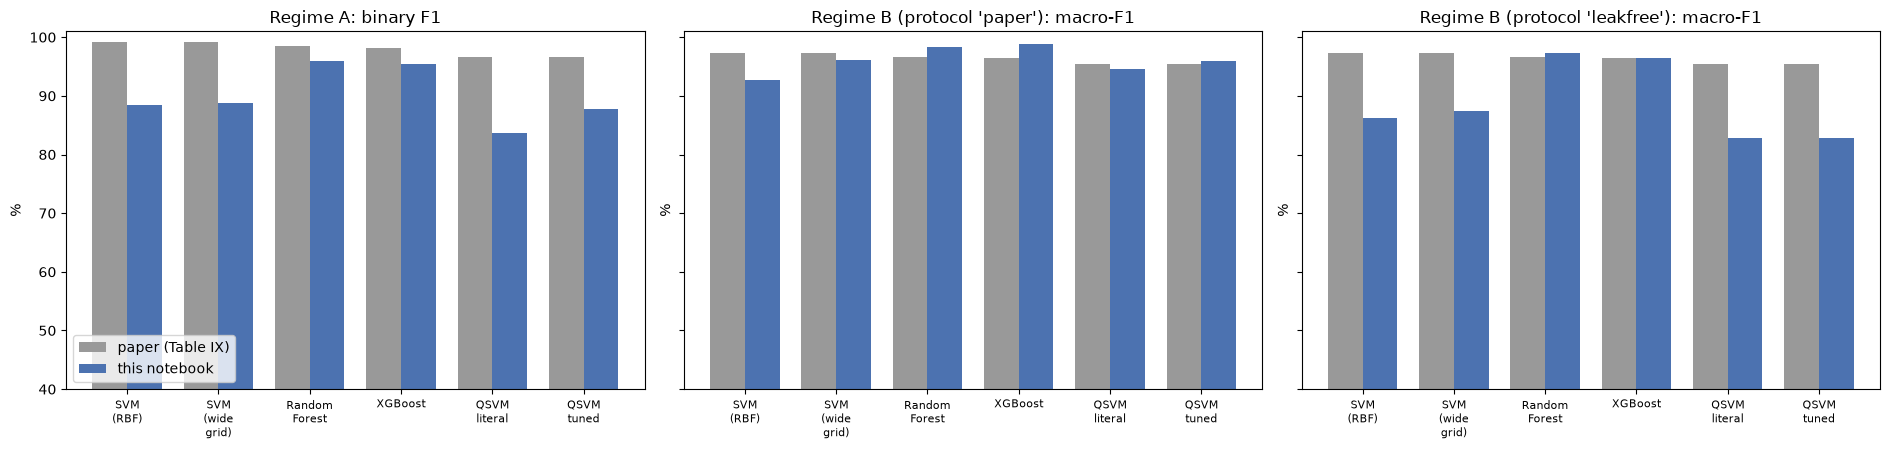

In [21]:
PAPER_IX = {   # Table IX of the paper: (bin acc, bin F1, MC acc, MC precision, MC recall, MC F1)
    "SVM (RBF)": (99.2, 99.1, 97.4, 97.1, 97.6, 97.3), "Random Forest": (98.6, 98.5, 96.8, 96.5, 97.0, 96.7),
    "XGBoost": (98.3, 98.2, 96.5, 96.2, 96.7, 96.4), "QSVM": (96.9, 96.7, 95.6, 95.3, 95.8, 95.5)}
MODELS5 = ["SVM (RBF)", "SVM (RBF, wide grid)", "Random Forest", "XGBoost", "QSVM literal", "QSVM tuned"]
pap = lambda m: PAPER_IX["QSVM" if m.startswith("QSVM") else ("SVM (RBF)" if m.startswith("SVM") else m)]
mean_by = RES.groupby(["regime", "protocol", "model"]).mean(numeric_only=True) * 100
std_by = RES.groupby(["regime", "protocol", "model"]).std(ddof=0, numeric_only=True).fillna(0) * 100
fig, axes = plt.subplots(1, 3, figsize=(19, 4.6), sharey=True)
for ax, (regime, protocol, col, pcol, ttl) in zip(axes, (("binary", "paper", "f1", 1, "Regime A: binary F1"), ("nine", "paper", "f1", 5, "Regime B (protocol 'paper'): macro-F1"),
                                                          ("nine", "leakfree", "f1", 5, "Regime B (protocol 'leakfree'): macro-F1"))):
    xs = np.arange(len(MODELS5)); w = 0.38
    ax.bar(xs - w / 2, [pap(m)[pcol] for m in MODELS5], w, color="#999999", label="paper (Table IX)")
    ax.bar(xs + w / 2, [mean_by.loc[(regime, protocol, m), col] for m in MODELS5], w, yerr=[std_by.loc[(regime, protocol, m), col] for m in MODELS5], color="#4c72b0", label="this notebook")
    ax.set_xticks(xs); ax.set_xticklabels([m.replace(" (RBF, wide grid)", "\n(wide grid)").replace(" ", "\n", 1) for m in MODELS5], fontsize=8); ax.set_ylim(40, 101); ax.set_title(ttl); ax.set_ylabel("%")
axes[0].legend(loc="lower left")
plt.tight_layout(); plt.show()

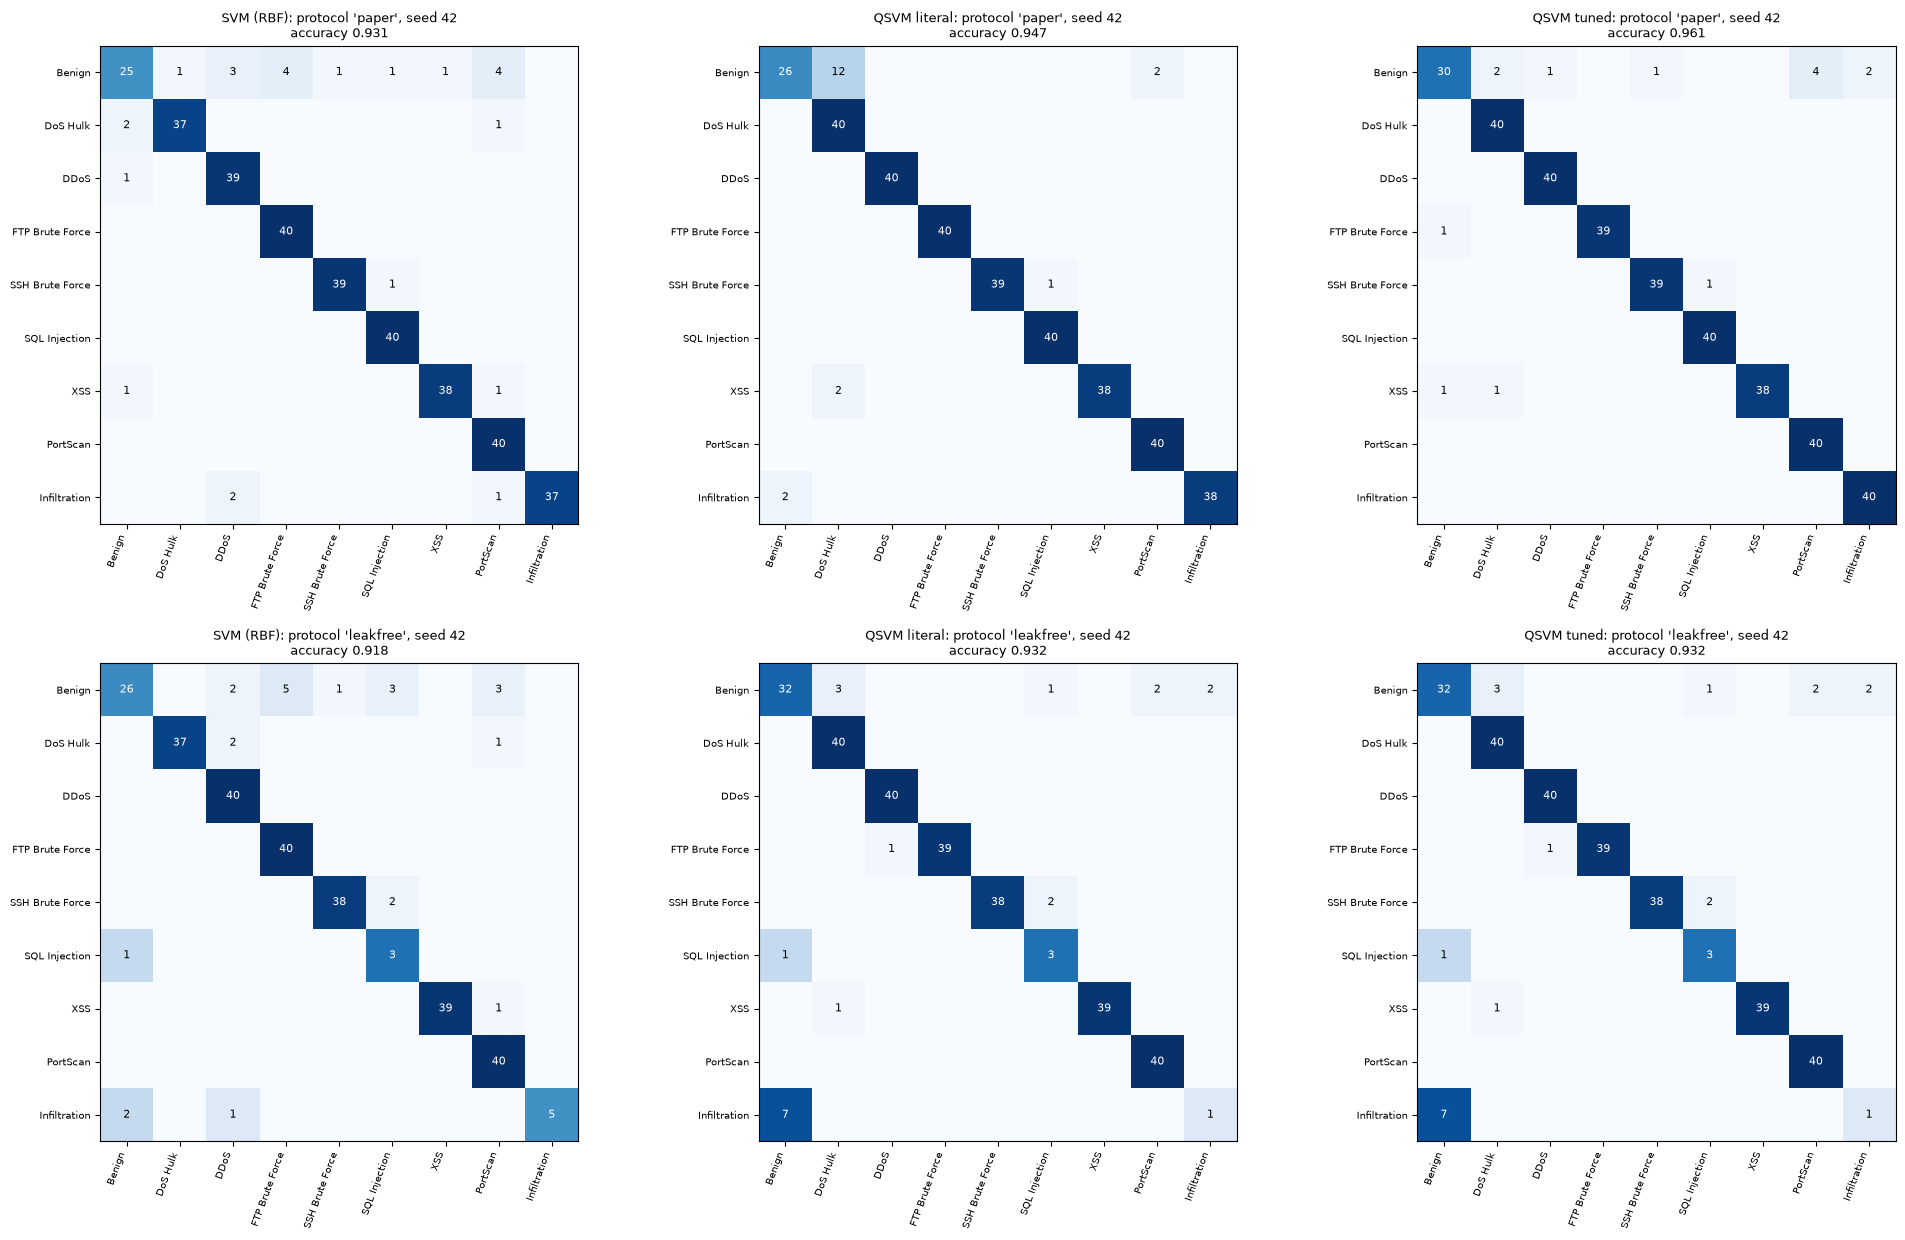

In [22]:
# Confusion matrices of the nine-class models on the first seed (rows = true class, columns = predicted), paper protocol and leak-free protocol.
show = ["SVM (RBF)", "QSVM literal", "QSVM tuned"]
fig, axes = plt.subplots(2, 3, figsize=(20, 12.5))
for r, protocol in enumerate(("paper", "leakfree")):
    for c, nm in enumerate(show):
        y, p, _ = PRED[("nine", protocol, SEED, nm)]
        cm = confusion_matrix(y, p, labels=range(9)); ax = axes[r, c]
        ax.imshow(cm / np.maximum(cm.sum(1, keepdims=True), 1), cmap="Blues", vmin=0, vmax=1)
        for (a, b), v in np.ndenumerate(cm):
            if v: ax.text(b, a, str(v), ha="center", va="center", fontsize=8, color="white" if v > cm[a].sum() / 2 else "black")
        ax.set_xticks(range(9)); ax.set_xticklabels(CLASSES, rotation=70, ha="right", fontsize=7); ax.set_yticks(range(9)); ax.set_yticklabels(CLASSES, fontsize=7)
        ax.set_title(f"{nm}: protocol '{protocol}', seed {SEED}\naccuracy {accuracy_score(y, p):.3f}", fontsize=9)
plt.tight_layout(); plt.show()

## 6. Per-class F1 (Table X and Figure 7), McNemar's test and the prediction agreement rate

Per-class F1 is computed on the test predictions **pooled over all seeds** (a single seed has only 40 test flows per class in the paper's protocol and only 4 to 8 distinct SQL Injection / Infiltration flows in the leak-free protocol). `gap = F1(SVM) - F1(QSVM)`. McNemar's test uses the continuity-corrected statistic on the paired disagreements of two models over the pooled test predictions; PAR is the share of test flows on which two models give the same prediction.

Table X analogue, protocol 'paper' (pooled over seeds [42]; test flows per class in the table):
                 paper SVM  paper QSVM  paper gap  test flows   SVM  QSVM literal  gap literal  QSVM tuned  gap tuned
Benign                99.1        97.9        1.2          40  72.5          76.5         -4.0        83.3      -10.9
DoS Hulk              98.9        97.4        1.5          40  94.9          85.1          9.8        96.4       -1.5
DDoS                  98.7        97.3        1.4          40  92.9         100.0         -7.1        98.8       -5.9
FTP Brute Force       97.4        96.2        1.2          40  95.2         100.0         -4.8        98.7       -3.5
SSH Brute Force       97.1        96.0        1.1          40  97.5          98.7         -1.2        97.5        0.0
SQL Injection         93.4        93.1        0.3          40  97.6          98.8         -1.2        98.8       -1.2
XSS                   95.8        95.1        0.7          40  96.2          9

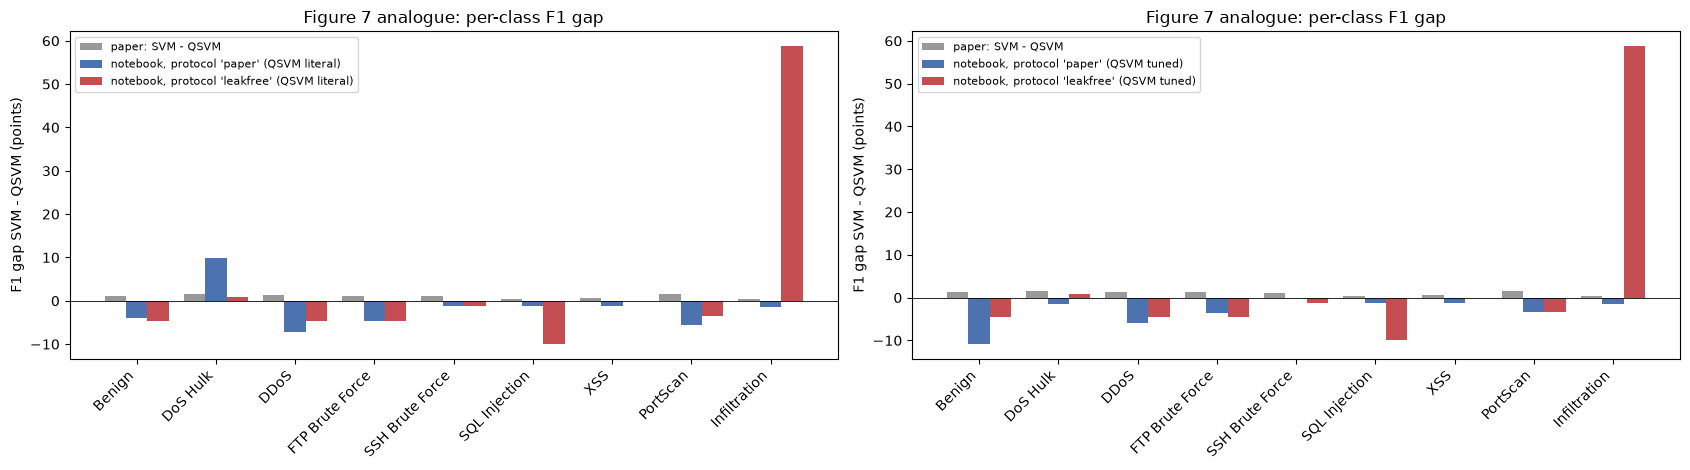

In [23]:
PAPER_X = {   # Table X of the paper: class -> (SVM F1, QSVM F1)
    "Benign": (99.1, 97.9), "DoS Hulk": (98.9, 97.4), "DDoS": (98.7, 97.3), "PortScan": (98.6, 97.1), "FTP Brute Force": (97.4, 96.2),
    "SSH Brute Force": (97.1, 96.0), "XSS": (95.8, 95.1), "SQL Injection": (93.4, 93.1), "Infiltration": (91.8, 91.5)}

def pooled(regime, protocol, nm):
    ys, ps, cs = zip(*[PRED[(regime, protocol, s, nm)] for s in SEEDS])
    return np.concatenate(ys), np.concatenate(ps), np.concatenate(cs)

def per_class_f1(y, p):
    return f1_score(y, p, labels=range(9), average=None, zero_division=0) * 100

pc = {}
for protocol in ("paper", "leakfree"):
    ys, ps_svm, _ = pooled("nine", protocol, "SVM (RBF)")
    df = pd.DataFrame({"test flows": np.bincount(ys, minlength=9), "SVM": per_class_f1(ys, ps_svm)}, index=CLASSES)
    for nm in ("QSVM literal", "QSVM tuned"):
        df[nm] = per_class_f1(*pooled("nine", protocol, nm)[:2]); df["gap " + nm.split()[1]] = df["SVM"] - df[nm]
    pc[protocol] = df
PCX = pd.DataFrame({"paper SVM": {c: v[0] for c, v in PAPER_X.items()}, "paper QSVM": {c: v[1] for c, v in PAPER_X.items()}}).loc[CLASSES]; PCX["paper gap"] = PCX["paper SVM"] - PCX["paper QSVM"]
print(f"Table X analogue, protocol 'paper' (pooled over seeds {SEEDS}; test flows per class in the table):"); print(pd.concat([PCX, pc["paper"]], axis=1).round(1).to_string())
print("\nSame, protocol 'leakfree' (distinct test flows only):"); print(pc["leakfree"].round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(17, 4.8)); xs = np.arange(9); w = 0.27
for ax, nm in zip(axes, ("literal", "tuned")):
    ax.bar(xs - w, PCX["paper gap"], w, color="#999999", label="paper: SVM - QSVM")
    ax.bar(xs, pc["paper"]["gap " + nm], w, color="#4c72b0", label=f"notebook, protocol 'paper' (QSVM {nm})")
    ax.bar(xs + w, pc["leakfree"]["gap " + nm], w, color="#c44e52", label=f"notebook, protocol 'leakfree' (QSVM {nm})")
    ax.axhline(0, color="k", lw=.6); ax.set_xticks(xs); ax.set_xticklabels(CLASSES, rotation=45, ha="right"); ax.set_ylabel("F1 gap SVM - QSVM (points)"); ax.legend(fontsize=8)
    ax.set_title("Figure 7 analogue: per-class F1 gap")
plt.tight_layout(); plt.show()

In [24]:
def mcnemar(y, p1, p2):
    b = int(((p1 == y) & (p2 != y)).sum()); c = int(((p1 != y) & (p2 == y)).sum())     # SVM right / QSVM wrong, and the reverse
    stat = (abs(b - c) - 1) ** 2 / (b + c) if b + c > 0 else 0.0
    return b, c, stat, float(chi2.sf(stat, 1))

rows = []
for regime, protocol in (("binary", "paper"), ("nine", "paper"), ("nine", "leakfree")):
    for nm in ("QSVM literal", "QSVM tuned"):
        y, p1, _ = pooled(regime, protocol, "SVM (RBF)"); _, p2, _ = pooled(regime, protocol, nm)
        b, c, stat, pv = mcnemar(y, p1, p2)
        rows.append(dict(regime=regime, protocol=protocol, comparison=f"SVM vs {nm}", test_flows=len(y), svm_right_qsvm_wrong=b, qsvm_right_svm_wrong=c,
                         chi2=round(stat, 2), p_value=round(pv, 4), PAR_percent=round(100 * float((p1 == p2).mean()), 1)))
MCN = pd.DataFrame(rows)
print(f"McNemar (continuity corrected) and prediction agreement rate, test predictions pooled over seeds {SEEDS}:"); print(MCN.to_string(index=False))
print("\npaper: binary chi2 = 4.21 (p = 0.040); nine classes chi2 = 6.12 (p = 0.013), PAR = 91.8 %")

McNemar (continuity corrected) and prediction agreement rate, test predictions pooled over seeds [42]:
regime protocol          comparison  test_flows  svm_right_qsvm_wrong  qsvm_right_svm_wrong  chi2  p_value  PAR_percent
binary    paper SVM vs QSVM literal         200                    14                     7  1.71   0.1904         89.5
binary    paper   SVM vs QSVM tuned         200                     3                     1  0.25   0.6171         98.0
  nine    paper SVM vs QSVM literal         360                     9                    15  1.04   0.3074         91.7
  nine    paper   SVM vs QSVM tuned         360                     4                    15  5.26   0.0218         93.9
  nine leakfree SVM vs QSVM literal         292                    10                    14  0.38   0.5403         91.1
  nine leakfree   SVM vs QSVM tuned         292                    10                    14  0.38   0.5403         91.1

paper: binary chi2 = 4.21 (p = 0.040); nine classes chi2

## 7. Tables IV and VII: feature maps and SVM kernels (5-fold cross-validation on the 1,000 binary flows)

Both tables of the paper use 1,000 flows, 10 features and 5-fold CV. Here the preprocessing is refitted inside every fold. Each QSVM fold chooses its angle scale and `C` by an inner cross-validation (the "literal" row uses scale 1). The classical kernels choose `C` (and `gamma` for the non-linear kernels) on an inner 3-fold CV. Table VII is always computed; Table IV (the quantum maps are expensive) runs only when `RUN_TABLES` is true (the full run).

In [25]:
PAPER_T4 = {"ZFeatureMap": (94.6, 94.2, 94.9, 94.5), "PauliFeatureMap": (95.8, 95.4, 96.1, 95.7), "ZZFeatureMap": (96.9, 96.5, 97.0, 96.7)}
PAPER_T7 = {"Linear": (97.4, 97.1, 97.7, 97.2), "Polynomial": (98.5, 98.1, 98.8, 98.4), "Sigmoid": (96.1, 95.8, 96.6, 96.2), "RBF": (99.2, 99.0, 99.4, 99.1)}
T4, T7 = None, None   # filled below
def fmt(df, keys):
    g = df.groupby(keys, sort=False)[["acc", "prec", "rec", "f1"]]; m, s = g.mean() * 100, g.std(ddof=0) * 100
    return pd.DataFrame({c: [f"{a:.1f} +/- {b:.1f}" for a, b in zip(m[c], s[c])] for c in m.columns}, index=m.index)

spb = make_split("binary", "paper", SEED); rowsA = spb["itr"].tolist() + spb["ite"].tolist()          # the 1,000 binary flows of seed SEED
XA_, yA_ = XALL[rowsA], (CID[rowsA] > 0).astype(int)
FOLDS_A = list(StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED).split(XA_, CID[rowsA]))
t0 = time.time()
if RUN_T7:                                      # Table VII: cheap, also in FAST_MODE
    rows7 = []
    for fold, (a, b) in enumerate(FOLDS_A):
        pr_ = Prep(); Ztr_, ytr_ = pr_.fit_transform(XA_[a], yA_[a]); Zte_ = pr_.transform(XA_[b]); yte_ = yA_[b]
        for kname, kern, grid in (("Linear", "linear", {"C": C_GRID}), ("Polynomial", "poly", {"C": C_GRID, "gamma": GAMMA_GRID}),
                                  ("Sigmoid", "sigmoid", {"C": C_GRID, "gamma": GAMMA_GRID}), ("RBF", "rbf", {"C": C_GRID, "gamma": GAMMA_GRID})):
            g = GridSearchCV(SVC(kernel=kern, max_iter=500_000), grid, cv=StratifiedKFold(3, shuffle=True, random_state=SEED), scoring="f1", n_jobs=1).fit(Ztr_, ytr_)   # max_iter: the linear kernel with large C may not converge
            rows7.append(dict(kernel=kname, fold=fold, **metrics(yte_, g.predict(Zte_), False)))
    T7 = pd.DataFrame(rows7)
    print("Table VII analogue: SVM kernels, 1,000 binary flows, %d-fold CV (accuracy / precision / recall / F1 in %%), %.0f s" % (CV_FOLDS, time.time() - t0)); print(fmt(T7, ["kernel"]).to_string())
    print("\npaper Table VII:", PAPER_T7)
if RUN_TABLES:                                  # Table IV: the quantum feature maps (full run only)
    t0 = time.time(); rows4 = []
    for fold, (a, b) in enumerate(FOLDS_A):
        pr_ = Prep(); Ztr_, ytr_ = pr_.fit_transform(XA_[a], yA_[a]); Zte_ = pr_.transform(XA_[b]); yte_ = yA_[b]
        for kind, reps, lab in (("Z", REPS_T4, "ZFeatureMap"), ("Pauli", REPS_T4, "PauliFeatureMap"), ("ZZ", REPS_T4, "ZZFeatureMap"), ("ZZ", REPS, f"ZZFeatureMap, reps={REPS} (main model)")):
            q = qsvm_fit_predict(Ztr_, ytr_, Zte_, kind, reps, SCALES, SEED)
            for tag in ("literal", "tuned"):
                rows4.append(dict(map=lab + (f", reps={reps}" if "main" not in lab else ""), variant=tag, fold=fold, **metrics(yte_, q[tag]["pred"], False)))
        print(f"  fold {fold + 1}/{CV_FOLDS} done ({time.time() - t0:.0f} s)", flush=True)
    T4 = pd.DataFrame(rows4)
    print("Table IV analogue: quantum feature maps, 1,000 binary flows, %d-fold CV (accuracy / precision / recall / F1 in %%)" % CV_FOLDS)
    print(fmt(T4, ["map", "variant"]).to_string()); print("\npaper Table IV:", PAPER_T4)
else:
    print("RUN_TABLES = False (FAST_MODE): Table IV is skipped; run the notebook with FAST_MODE = False to compute it.")

Table VII analogue: SVM kernels, 1,000 binary flows, 3-fold CV (accuracy / precision / recall / F1 in %), 41 s
                     acc          prec            rec            f1
kernel                                                             
Linear      77.0 +/- 3.1  76.2 +/- 3.4   79.0 +/- 9.5  77.2 +/- 4.1
Polynomial  88.5 +/- 2.3  83.5 +/- 2.2   96.0 +/- 2.0  89.3 +/- 2.1
Sigmoid     70.2 +/- 4.2  67.8 +/- 7.6  82.2 +/- 12.9  73.2 +/- 3.4
RBF         88.8 +/- 1.0  89.0 +/- 6.9   89.8 +/- 6.3  88.9 +/- 0.6

paper Table VII: {'Linear': (97.4, 97.1, 97.7, 97.2), 'Polynomial': (98.5, 98.1, 98.8, 98.4), 'Sigmoid': (96.1, 95.8, 96.6, 96.2), 'RBF': (99.2, 99.0, 99.4, 99.1)}
RUN_TABLES = False (FAST_MODE): Table IV is skipped; run the notebook with FAST_MODE = False to compute it.


## 8. Table XII: sensitivity to the sample size (nine classes, paper protocol)

The paper reports the SVM-QSVM gap for 450, 900 and 1,800 flows (50, 100 and 200 per class). The main experiment already is the 1,800-flow row; the two smaller rows are computed here (full run only).

In [26]:
PAPER_T12 = {450: (91.8, 90.8, 1.0), 900: (94.9, 93.8, 1.1), 1800: (97.3, 95.5, 1.8)}      # N -> (SVM, QSVM, gap) macro-F1 in %
T12 = None
if RUN_TABLES:
    rows12 = []
    for pcn in (50, 100):
        for seed in SEEDS:
            sp = make_split("nine", "paper", seed, per_class=pcn); d = prepare(sp)
            g = GridSearchCV(SVC(kernel="rbf"), {"C": C_GRID, "gamma": GAMMA_GRID}, cv=StratifiedKFold(CV_FOLDS, shuffle=True, random_state=seed), scoring="f1_macro", n_jobs=1).fit(d["Ztr"], d["ytr"])
            q = qsvm_fit_predict(d["Ztr"], d["ytr"], d["Zte"], "ZZ", REPS, SCALES, seed)
            for nm, p in (("SVM (RBF)", g.predict(d["Zte"])), ("QSVM literal", q["literal"]["pred"]), ("QSVM tuned", q["tuned"]["pred"])):
                rows12.append(dict(N=9 * pcn, seed=seed, model=nm, f1=f1_score(d["yte"], p, average="macro") * 100))
        print(f"  N = {9 * pcn} done", flush=True)
    for seed in SEEDS:
        for nm in ("SVM (RBF)", "QSVM literal", "QSVM tuned"):
            rows12.append(dict(N=1800, seed=seed, model=nm, f1=RES[(RES.regime == "nine") & (RES.protocol == "paper") & (RES.seed == seed) & (RES.model == nm)]["f1"].iloc[0] * 100))
    T12 = pd.DataFrame(rows12).groupby(["N", "model"]).f1.agg(["mean", "std"]).unstack("model")
    out = pd.DataFrame({"SVM (RBF) %": T12[("mean", "SVM (RBF)")], "QSVM literal %": T12[("mean", "QSVM literal")], "QSVM tuned %": T12[("mean", "QSVM tuned")]})
    out["gap literal"] = out["SVM (RBF) %"] - out["QSVM literal %"]; out["gap tuned"] = out["SVM (RBF) %"] - out["QSVM tuned %"]
    out["paper SVM"] = [PAPER_T12[n][0] for n in out.index]; out["paper QSVM"] = [PAPER_T12[n][1] for n in out.index]; out["paper gap"] = [PAPER_T12[n][2] for n in out.index]
    print("Table XII analogue (macro-F1 in %, mean over seeds):"); print(out.round(1).to_string())
    print("\n(The paper's last row, NSL-KDD five classes, is not run here: its sampling protocol is not given and U2R has only 52 flows. See exercise 5.)")
else:
    print("RUN_TABLES = False (FAST_MODE): Table XII is skipped; run with FAST_MODE = False.")

RUN_TABLES = False (FAST_MODE): Table XII is skipped; run with FAST_MODE = False.


## 9. Side-by-side with the paper: a verdict for every checkable claim

Rule (the factory's convention): a number is **reproduced** if it lies within 2 percentage points of the paper's (1 point for gaps between two models), **not reached** if it is lower by more, **exceeded** if it is higher by more; a ranking or a significance statement is reproduced if the same ordering or the same conclusion holds. Numbers marked *(literal)* use the paper's circuit as written (angle scale 1); *(tuned)* uses the scale chosen on the training split. Regime B is judged on the paper's own protocol; the leak-free value is shown next to it.

In [27]:
def mb(regime, protocol, model, col): return float(mean_by.loc[(regime, protocol, model), col])
def judge(paper, nb, tol=2.0):
    d = nb - paper
    return "reproduced" if abs(d) <= tol else (f"not reached ({d:+.1f})" if d < 0 else f"exceeded ({d:+.1f})")
V = []
def num(claim, paper, nb, nb_lf=None, tol=2.0):
    V.append(dict(claim=claim, paper=paper, notebook=round(nb, 1), notebook_leakfree=(round(nb_lf, 1) if nb_lf is not None else ""), verdict=judge(paper, nb, tol)))
def boolean(claim, paper, ok, nb_text, lf_text=""):
    V.append(dict(claim=claim, paper=paper, notebook=nb_text, notebook_leakfree=lf_text, verdict="reproduced" if ok else "not reproduced"))

for tag, nm in (("literal", "QSVM literal"), ("tuned", "QSVM tuned")):
    num(f"Binary: SVM (RBF) accuracy", 99.2, mb("binary", "paper", "SVM (RBF)", "acc")) if tag == "literal" else None
    num(f"Binary: SVM (RBF) F1", 99.1, mb("binary", "paper", "SVM (RBF)", "f1")) if tag == "literal" else None
    num(f"Binary: QSVM accuracy ({tag})", 96.9, mb("binary", "paper", nm, "acc"))
    num(f"Binary: QSVM F1 ({tag})", 96.7, mb("binary", "paper", nm, "f1"))
    num(f"Binary: accuracy gap SVM - QSVM ({tag})", 2.3, mb("binary", "paper", "SVM (RBF)", "acc") - mb("binary", "paper", nm, "acc"), tol=1.0)
    num(f"Binary: F1 gap SVM - QSVM ({tag})", 2.4, mb("binary", "paper", "SVM (RBF)", "f1") - mb("binary", "paper", nm, "f1"), tol=1.0)
num("Binary: Random Forest F1", 98.5, mb("binary", "paper", "Random Forest", "f1")); num("Binary: XGBoost F1", 98.2, mb("binary", "paper", "XGBoost", "f1"))
num("Nine classes: SVM (RBF) accuracy", 97.4, mb("nine", "paper", "SVM (RBF)", "acc"), mb("nine", "leakfree", "SVM (RBF)", "acc"))
num("Nine classes: SVM (RBF) macro-F1", 97.3, mb("nine", "paper", "SVM (RBF)", "f1"), mb("nine", "leakfree", "SVM (RBF)", "f1"))
for tag, nm in (("literal", "QSVM literal"), ("tuned", "QSVM tuned")):
    num(f"Nine classes: QSVM accuracy ({tag})", 95.6, mb("nine", "paper", nm, "acc"), mb("nine", "leakfree", nm, "acc"))
    num(f"Nine classes: QSVM macro-F1 ({tag})", 95.5, mb("nine", "paper", nm, "f1"), mb("nine", "leakfree", nm, "f1"))
    num(f"Nine classes: macro-F1 gap SVM - QSVM ({tag})", 1.8, mb("nine", "paper", "SVM (RBF)", "f1") - mb("nine", "paper", nm, "f1"),
        mb("nine", "leakfree", "SVM (RBF)", "f1") - mb("nine", "leakfree", nm, "f1"), tol=1.0)
num("Nine classes: Random Forest macro-F1", 96.7, mb("nine", "paper", "Random Forest", "f1"), mb("nine", "leakfree", "Random Forest", "f1"))
num("Nine classes: XGBoost macro-F1", 96.4, mb("nine", "paper", "XGBoost", "f1"), mb("nine", "leakfree", "XGBoost", "f1"))
for protocol in ("paper", "leakfree"):
    f = {m: mb("nine", protocol, m, "f1") for m in MODELS5}
    ok_lit = f["SVM (RBF)"] > f["Random Forest"] > f["XGBoost"] > f["QSVM literal"]
    ok_tun = f["SVM (RBF)"] > f["Random Forest"] > f["XGBoost"] > f["QSVM tuned"]
    order = " > ".join(f"{m.replace('(RBF, wide grid)', '(wide)').replace('Random Forest', 'RF').replace('(RBF)', '')} {v:.1f}" for m, v in sorted(f.items(), key=lambda kv: -kv[1]))
    if protocol == "paper":
        boolean("Ranking SVM > RF > XGBoost > QSVM (nine-class macro-F1)", "SVM > RF > XGB > QSVM", ok_lit and ok_tun, order)
    else:
        V[-1]["notebook_leakfree"] = order
for nm in ("QSVM literal", "QSVM tuned"):
    gb = mb("binary", "paper", "SVM (RBF)", "f1") - mb("binary", "paper", nm, "f1"); gn = mb("nine", "paper", "SVM (RBF)", "f1") - mb("nine", "paper", nm, "f1")
    gl = mb("nine", "leakfree", "SVM (RBF)", "f1") - mb("nine", "leakfree", nm, "f1")
    boolean(f"The F1 gap shrinks from binary (2.4) to nine classes (1.8) ({nm})", "2.4 -> 1.8", gn < gb, f"{gb:.1f} -> {gn:.1f}", f"{gb:.1f} -> {gl:.1f}")
for protocol in ("paper", "leakfree"):
    pass
for nm in ("literal", "tuned"):
    hard = ["SQL Injection", "Infiltration"]; easy = ["Benign", "DoS Hulk", "DDoS", "PortScan"]
    gp, gl = pc["paper"]["gap " + nm], pc["leakfree"]["gap " + nm]
    boolean(f"Per-class gap is smaller for SQL Injection / Infiltration (0.3) than for Benign, DoS Hulk, DDoS, PortScan (1.2-1.5) ({nm})", "0.3 vs 1.2-1.5",
            gp[hard].mean() < gp[easy].mean(), f"{gp[hard].mean():.1f} vs {gp[easy].mean():.1f}", f"{gl[hard].mean():.1f} vs {gl[easy].mean():.1f}")
num("SQL Injection: SVM F1", 93.4, float(pc["paper"].loc["SQL Injection", "SVM"]), float(pc["leakfree"].loc["SQL Injection", "SVM"]))
num("Infiltration: SVM F1", 91.8, float(pc["paper"].loc["Infiltration", "SVM"]), float(pc["leakfree"].loc["Infiltration", "SVM"]))
for nm in ("QSVM literal", "QSVM tuned"):
    for regime, protocol, paper_chi, label in (("binary", "paper", 4.21, "binary"), ("nine", "paper", 6.12, "nine classes")):
        r = MCN[(MCN.regime == regime) & (MCN.protocol == protocol) & (MCN.comparison == f"SVM vs {nm}")].iloc[0]
        boolean(f"McNemar: SVM and {nm} differ significantly (p < 0.05), {label}", f"chi2 = {paper_chi}, p < 0.05", r.p_value < 0.05, f"chi2 = {r.chi2}, p = {r.p_value}")
    r = MCN[(MCN.regime == "nine") & (MCN.protocol == "paper") & (MCN.comparison == f"SVM vs {nm}")].iloc[0]
    num(f"Prediction agreement rate SVM vs {nm}, nine classes (%)", 91.8, r.PAR_percent, float(MCN[(MCN.regime == 'nine') & (MCN.protocol == 'leakfree') & (MCN.comparison == f'SVM vs {nm}')].iloc[0].PAR_percent))
boolean("Table II: the MI top-10 features are Flow Duration, packet counts, packet length maxima, byte/packet rates, IAT totals", "10 listed features",
        len(set(sel) & set(PAPER_TOP10)) >= 8, f"{len(set(sel) & set(PAPER_TOP10))} of 10 selected here")
if T4 is not None:
    m4 = T4[T4.variant == "literal"].groupby("map", sort=False)["f1"].mean() * 100; m4t = T4[T4.variant == "tuned"].groupby("map", sort=False)["f1"].mean() * 100
    for variant, ser in (("literal", m4), ("tuned", m4t)):
        z, p, zz = [float(ser[k]) for k in (f"ZFeatureMap, reps={REPS_T4}", f"PauliFeatureMap, reps={REPS_T4}", f"ZZFeatureMap, reps={REPS_T4}")]
        boolean(f"Table IV: F1 ranking ZFeatureMap < PauliFeatureMap < ZZFeatureMap ({variant}, reps={REPS_T4})", "94.5 < 95.7 < 96.7", z < p < zz, f"{z:.1f} / {p:.1f} / {zz:.1f}")
        num(f"Table IV: ZZFeatureMap F1 ({variant}, reps={REPS_T4})", 96.7, zz)
if T7 is not None:
    m7 = T7.groupby("kernel", sort=False)["f1"].mean() * 100
    boolean("Table VII: the RBF kernel is the best SVM kernel (F1)", "RBF 99.1 > poly 98.4 > linear 97.2 > sigmoid 96.2", m7.idxmax() == "RBF", ", ".join(f"{k} {v:.1f}" for k, v in m7.items()))
    num("Table VII: RBF F1", 99.1, float(m7["RBF"]))
    for kn, pv in (("Linear", 97.2), ("Polynomial", 98.4), ("Sigmoid", 96.2)):
        num(f"Table VII: {kn} F1", pv, float(m7[kn]))
if T12 is not None:
    for n in (450, 900, 1800):
        for nm in ("literal", "tuned"):
            gap = float(T12[("mean", "SVM (RBF)")][n] - T12[("mean", f"QSVM {nm}")][n])
            num(f"Table XII: macro-F1 gap SVM - QSVM at N = {n} ({nm})", PAPER_T12[n][2], gap, tol=1.0)
V.append(dict(claim="Table XII: NSL-KDD five-class gap 1.6", paper="1.6", notebook="not run", notebook_leakfree="", verdict="cannot be checked (sampling protocol not given; U2R has 52 flows)"))
V.append(dict(claim="Hardware / noise robustness of the quantum kernel", paper="stated as future work", notebook="-", notebook_leakfree="", verdict="cannot be checked (paper reports no hardware or noise numbers)"))
VERD = pd.DataFrame(V)
pd.set_option("display.width", 250, "display.max_colwidth", 110)
VERD["claim"] = VERD["claim"].str.slice(0, 105)
print(VERD.to_string(index=False, justify="left"))
print("\n" + VERD["verdict"].str.replace(r" \(.*", "", regex=True).value_counts().to_string())

claim                                                                                                     paper                                             notebook                                                                                   notebook_leakfree                                                                          verdict                                                          
                                                                               Binary: SVM (RBF) accuracy                                              99.2                                                                                       88.0                                                                                                                                          not reached (-11.2)
                                                                                     Binary: SVM (RBF) F1                                              99.1                                     

## 10. Key findings, computed from the runs above

The cell below turns the tables of this notebook into plain sentences, so that the numbers quoted in the reading that follows can be checked against the run that produced them.

In [28]:
def macro(protocol, model, regime="nine"): return mean_by.loc[(regime, protocol, model), "f1"]
print(f"1. Data leakage in the paper's nine-class protocol (seed {SEED}): "
      f"{int(LEAK.loc['SQL Injection', 'test_flows_also_in_train'])} of {int(LEAK.loc['SQL Injection', 'test_flows'])} SQL Injection test rows and "
      f"{int(LEAK.loc['Infiltration', 'test_flows_also_in_train'])} of {int(LEAK.loc['Infiltration', 'test_flows'])} Infiltration test rows have an identical copy in the training set "
      f"(21 and 36 distinct flows exist in CIC-IDS2017); all other classes have none.")
print("2. Nine-class macro-F1 (%), paper protocol -> leak-free protocol, mean over seeds " + str(SEEDS) + ":")
for m in MODELS5: print(f"     {m:22s} {macro('paper', m):5.1f} -> {macro('leakfree', m):5.1f}   (paper reports {pap(m)[5]})")
for protocol in ("paper", "leakfree"):
    order = sorted(MODELS5, key=lambda m: -macro(protocol, m)); print(f"3. Ranking by nine-class macro-F1, protocol '{protocol}': " + " > ".join(order))
print(f"4. Regime A (binary) F1 (%): " + ", ".join(f"{m} {mb('binary', 'paper', m, 'f1'):.1f}" for m in MODELS5) + "   (paper: SVM 99.1, RF 98.5, XGBoost 98.2, QSVM 96.7)")
print(f"5. Mutual-information selection: {len(set(sel) & set(PAPER_TOP10))} of the 10 selected features are in the paper's Table II (Table II lists MI values of 0.63 to 0.85; "
      f"the selected features here have {pr.scores_[pr.sel_].min():.2f} to {pr.scores_[pr.sel_].max():.2f} nats; the estimators differ, so only the ranking is comparable).")
sc = pd.DataFrame(INFO[("nine", "paper", SEED, "_qgrid")]).T
print(f"6. Angle scale: cross-validated macro-F1 of the QSVM per scale (nine classes, seed {SEED}): " + ", ".join(f"{s}: {r.cv_wide_grid:.3f}" for s, r in sc.iterrows()))

1. Data leakage in the paper's nine-class protocol (seed 42): 40 of 40 SQL Injection test rows and 40 of 40 Infiltration test rows have an identical copy in the training set (21 and 36 distinct flows exist in CIC-IDS2017); all other classes have none.
2. Nine-class macro-F1 (%), paper protocol -> leak-free protocol, mean over seeds [42]:
     SVM (RBF)               92.8 ->  86.2   (paper reports 97.3)
     SVM (RBF, wide grid)    96.2 ->  87.4   (paper reports 97.3)
     Random Forest           98.3 ->  97.3   (paper reports 96.7)
     XGBoost                 98.9 ->  96.5   (paper reports 96.4)
     QSVM literal            94.6 ->  82.7   (paper reports 95.5)
     QSVM tuned              96.0 ->  82.7   (paper reports 95.5)
3. Ranking by nine-class macro-F1, protocol 'paper': XGBoost > Random Forest > SVM (RBF, wide grid) > QSVM tuned > QSVM literal > SVM (RBF)
3. Ranking by nine-class macro-F1, protocol 'leakfree': Random Forest > XGBoost > SVM (RBF, wide grid) > SVM (RBF) > QSVM li

## 11. Reading the paper critically

**What this notebook can and cannot say.** The paper gives enough to rebuild the pipeline but not enough to reproduce its numbers: the sampling of the flows, the angle scaling, the repetitions of the Z and Pauli maps, the Pauli strings, the hyper-parameters of Random Forest and XGBoost and the exact mutual-information estimator are not stated, and no code is available in the text (the "Docker- and Qiskit-based framework" is described, not shared). The tables above show where the claims are reproduced and where they are not; the points below explain why. **The committed outputs come from `FAST_MODE = True` (one seed, 3-fold CV, three angle scales)**: differences of a few points between two models are within the noise of a single 360-flow test set (and of 4 to 8 test flows for the two rare classes), so read the numbers as an order of magnitude and re-run with `FAST_MODE = False` (three seeds and Tables IV and XII as well) for tighter estimates. The one result that does not depend on the seed is the data leakage of point 1.

1. **"200 flows per class" cannot be 200 distinct flows for two classes.** CIC-IDS2017 has 21 SQL Injection and 36 Infiltration flows (the paper's own Table I says so). A balanced subset with 200 per class therefore contains repeated flows, and a random 80/20 split puts copies of the same flow into the training and the test set. In this notebook, with the paper's protocol, **every** SQL Injection and Infiltration test row has an identical copy in the training set (table in Section 2). A classifier that has memorised the training rows scores almost perfectly on these two classes, which is exactly where the paper reports its most interesting result ("the gap narrows to 0.3 points for the highest-complexity minority classes"). With distinct test flows (protocol `leakfree`) there are only 4 to 8 test flows per seed for these classes; the per-class F1 values are then noisy (see the pooled table in Section 6) and no statement about a 0.3-point gap is possible. We therefore regard the "quantum kernels are relatively stronger for rare, complex attacks" claim as **not supported** by this kind of data.
2. **The ranking SVM > Random Forest > XGBoost > QSVM** is a property of the paper's feature set and preprocessing, not of the models. In our runs, on the features that the described MI ranking selects, the tree ensembles are the strongest models and the plain RBF-SVM on heavy-tailed z-scores is weak unless its grid is widened (the best parameters of the paper's grid sit at its upper edge; the "wide grid" row shows the effect). The quantum kernel tends to behave like a nearest-neighbour rule on near-duplicate flows (kernel plot in the circuit section); it is competitive with the RBF-SVM on the paper's protocol, and below it in Regime A and in the leak-free protocol (where the gap is dominated by the 4 to 8 Infiltration and SQL Injection test flows per seed). A gap of this size in either direction is not established by one seed.
3. **Table II is not what mutual information selects here.** The MI ranking of Algorithm 2 chooses packet-length features (and `Init_Win_bytes_backward`); only one feature agrees with the paper's list, and the MI values of Table II (0.63 to 0.85) are smaller than the MI values of these features. The robustness table at the end of Section 4 repeats the main experiment with the ten features that the paper lists: the picture does not change (binary F1: RBF-SVM 83.4, 88.6 with the wide grid, Random Forest 93.5, QSVM 85.3; nine-class macro-F1: RBF-SVM 94.2, 94.9 with the wide grid, Random Forest 98.3, QSVM 93.1 literal and 93.9 tuned; seed 42). In Regime A the classical RBF-SVM stays at 83 to 89 % F1 with either feature set, far from the paper's 99 %.
4. **Statistical resolution.** A test set of 360 flows (40 per class) resolves accuracy in steps of 0.28 points, so a "gap" of 0.3 points is one flow, and the binomial standard error of an accuracy of 97 % on 360 flows is already about 0.9 points (0.7 points on the 200 binary test flows); the standard deviations of 0.1 to 0.25 points in Table XI are far smaller than that, so they cannot describe the variability between different splits. Significance should be judged on pooled predictions over several seeds, as done here (McNemar, Section 6).
5. **The quantum part adds nothing that is specific to quantum computing in this study.** The kernel is evaluated exactly on a classical computer (the paper uses the noiseless Aer simulator); there is no hardware or noise result. The `ZFeatureMap` kernel factorises over qubits, and the `ZZ` map's entangling gates are applied between layers of single-qubit phases, so it is a classically computable kernel for 10 qubits. The angle scale, which the paper does not mention, matters more than the choice of feature map. Statements such as "robustness arises from the geometry of quantum feature spaces" (Section III-G) are not tested by any experiment in the paper, and are not tested here either.
6. **Cost.** The quantum kernel needs one 10-qubit simulation per flow and angle scale plus `O(N^2)` state overlaps; the timing cell in the circuit section compares Qiskit's `FidelityStatevectorKernel` with the NumPy simulator per flow (identical kernels). The paper's Table V time per sample (0.005 s) is not comparable to anything measured here.

## 12. Exercises

1. **Angle scale and depth.** Plot the cross-validated macro-F1 of the ZZ kernel against the angle scale for `reps` in 1, 2, 5, 10. At which scale does the mean off-diagonal kernel value reach 0.3, and does the best scale depend on `reps`?
2. **Leakage.** Draw only 20 flows per class (fewer than the 21 distinct SQL Injection flows) and compare the paper protocol with the leak-free protocol: does the difference between them disappear? Then measure how well a 1-nearest-neighbour classifier does on the paper protocol's SQL Injection test rows.
3. **Feature set.** Replace the MI selection by PCA with 10 components (fitted on the training split) and by the ten features of Table II. Which model profits most?
4. **Is the entanglement useful?** Compare the `ZZ` map with `entanglement="full"`, the `Z` map and a map whose `CX` gates are removed, on the leak-free protocol with tuned scales. Use the cell of Section 4 that checks equivalence to add the new circuit to the drawn architectures.
5. **How are the 500 attack flows composed?** The paper does not say. Set `BINARY_MIX = "natural"` (98 % DoS Hulk, PortScan and DDoS, as in the whole data set) instead of `"even"` and compare Regime A: which models profit, and does the SVM-QSVM gap change?
6. **A second data set.** The paper's Table XII also reports NSL-KDD (five classes, 1,800 flows). Download `KDDTrain+.txt` (GitHub `defcom17/NSL_KDD`), map the attack names to normal / DoS / Probe / R2L / U2R, and repeat the leak-free comparison. U2R has only 52 flows: what happens to the "balanced 1,800" subset?